# **STEP 4, PART 1.3**

### **What did the asymmetry buy, where does the rest of the residual sit, and what does the covariance of the likelihood need to know?**

| section | question | uses |
|---|---|---|
| 1. Load | the stages, the checks (`PM1`, `PC1`, `PB1`, `P1`), the comparison grid | caches, run files |
| 2. The gain over G1, directly | at each residual's own optimum, how far is the asymmetric model below the symmetric one? Eight seeds each, no surface | replicates |
| 3. The north-south budget | how much of $R$ is the difference between LAB at $+b$ and at $-b$ (the part no symmetric model can fit), and what share has the asymmetry captured? | LAB only |
| 4.. The north halves as replicates | `M1` and `B1` share their design, and the north run does not know the south ratios: two independent measurements of one function. Also: what do the south ratios do to the south? | hemisphere caches |
| 5. Stage `PR1` (optional) | the three CGM ratios one at a time, and a hotter southern corona | one `heron` job of 64 runs |
| 6. A flux-scale difference | Marasco's SFR gives both hemispheres the same normalisation. If the south needs a different one (less gas / less SFR / quenching), how much of the "wind" gain is really that? Where, in $(l, b, v)$ and per hemisphere, does the asymmetric model beat the symmetric one? Is that the Magellanic Stream edge, unmasked material, or LAB's own south? | the packs (replicates) |
| 7. The footprint of the north-south floor | Of the part of $R$ that no symmetric model can fit, how much sits where one hemisphere has emission and the other has none? | LAB and one model |
| 8. `PR2` | the run file, and the analysis for after the job: R in $(m, c)$, each hemisphere with its own scale | one `heron` job, 66 runs |

All residuals are the nine keys of the grid searches (`abs`, `sq`, `rel` $\times$ base / `Mrsc` / `Li`). The noise unit is that of one $n = 40$ run (about 1.3 % of $R$).

## 0. Settings

In [1]:
import sys, re, json, pickle, time, os
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.optimize import nnls

sys.path.insert(1, "../EPG_Code/current_version_software")
sys.path.insert(1, "../EPG_Code/mw_addenda")
sys.path.insert(1, "../EPG_Code/fitting")

import grid_search as g
import grid_search_residuals as gr
import pack_grid as pg

# ---------------- where things are ----------------
WORK        = Path("./")                       # the step-4 folder: out_<STAGE>_*/, results_<STAGE>/, runs/
G1_DIR      = Path("../Grid_Search/results")   # the results folder of the symmetric grid search (G1)
G1_WORK     = G1_DIR.parent                    # its out_G1_*/, out_P1_*/, runs/
LAB_PATH    = "../Displays/lab.fit.gz"
PRODUCTS    = "../Convergence/lab_products.npz"
SFR_PROFILE = "../Tests/inputs/sfr_profile_marasco12.txt"
CONV        = Path("../Convergence/conv")
WORKERS     = 10
HERON_WORK  = "<redacted_for_privacy>"
PROBE_MIN, PROBE_MB, PROBE_N = 5.81, 1050.0, 40   # the time of the G1 job (an asymmetric model is x2 in gr.job_estimate) and the memory estimate of the asymmetric grid notebooks
HV0_MAX     = 120.0                            # the box of the grid searches
DIAG        = WORK / "diag_cache"              # everything this notebook writes (merged packs, fits, tables) goes here, never into the folders of the grid searches
DIAG.mkdir(exist_ok=True)

# ---------------- the stages ----------------
SYM  = dict(label="G1", stage="G1", check="P1", work=G1_WORK, res=G1_DIR)
ASYM = {"motion": dict(label="motion", stage="M1", check="PM1", work=WORK, res=WORK / "results_M1"),
        "cgm":    dict(label="cgm",    stage="C1", check="PC1", work=WORK, res=WORK / "results_C1"),
        "both":   dict(label="both",   stage="B1", check="PB1", work=WORK, res=WORK / "results_B1")}

# ---------------- the asymmetry of the runs (the same numbers as in the grid-search notebooks) ----------------
T_RATIO      = 1.12
GAMMA        = 5.0 / 3.0
RHO_RATIO    = T_RATIO ** (1.0 / (GAMMA - 1.0))
SOUTH_RATIOS = dict(south_vlag_ratio=T_RATIO, south_alpha_conds_ratio=RHO_RATIO, south_drag_ratio=RHO_RATIO)
V_MOTION_RANGE = (-60.0, 20.0)

# ---------------- the comparison with LAB: the same settings as the grid searches ----------------
B_CUT, L_CUT = 0, 0
V_DEV      = 35.0
REL_FLOOR  = 0.04

In [2]:
from mw_io import load_lab_products
from mw_display import Cube
from mw_cube import mirror_north_to_full_sky
from mw_mask import (disk_velocity_envelope, mask_disk_emission, mask_named_regions, flat_v_circ,
                     OUTER_ARM, GCP, EXTERNAL_GAL, MAGELLANIC)
from marasco_comp import *

def build_keep(cube_data, axes, bcut=None):
    l, b, v = axes
    bc = B_CUT if bcut is None else bcut
    vmin, vmax = disk_velocity_envelope(l, b, R0=8.275, v_circ_func=flat_v_circ(220.0))
    excl = mask_disk_emission(cube_data, v, vmin, vmax, v_dev_threshold=V_DEV, return_mask_only=True)
    excl |= mask_named_regions(l, b, v, [OUTER_ARM, GCP] + EXTERNAL_GAL + MAGELLANIC)
    excl |= (np.abs(b) < bc)[None, :, None]
    if L_CUT > 0: excl |= (np.abs((np.asarray(l, float) + 180.0) % 360.0 - 180.0) < L_CUT)[None, None, :]
    return ~excl

def to_full(cube_north, axes):
    full = mirror_north_to_full_sky(Cube(cube_north, *axes, "model"))
    return full.data, (full.l, full.b, full.v)

lab, l_lab, b_lab, v_lab, P = load_lab_products(PRODUCTS, lab_path=LAB_PATH, correction=False)
ax_lab = (l_lab, b_lab, v_lab); keep_lab = build_keep(lab, ax_lab)

SIGMA_NUM  = P.sigma_empty
T_M        = 0.04
K_L        = 2.0
RESIDUAL_SETS = {
    "base": dict(kind="soft"),
    "Mrsc": dict(kind="select", T=T_M, rel="max", blanks=False),
    "Li":   dict(kind="select", k=K_L, sigma=SIGMA_NUM, rel="max", blanks=True),
}
TAG = f"v{V_DEV:g}_L{L_CUT:g}_B{B_CUT:g}_f{REL_FLOOR:g}_T{T_M:g}_k{K_L:g}_s{SIGMA_NUM*1e3:.2f}"

cmp = MarascoComparison(lab, ax_lab, keep_lab, build_keep, to_full,
                        CompareConfig(beam_fwhm=8.0, sampling=4.0, dv=8.0),
                        rel_floor=REL_FLOOR, residual_sets=RESIDUAL_SETS)
cfg = cmp.cfg
KEYS = list(cmp.keys)
print(f"Residual settings tag {TAG}\nComparison grid {len(cmp.v)} channels x {len(cmp.b)} b x {len(cmp.l)} l; keys: {KEYS}")

# the noise of one n = 40 run, per residual (convergence study)
PK_CONV = CONV / f"marasco_conv_{TAG}.pkl"
RES_CONV = pickle.load(open(PK_CONV, "rb")) if PK_CONV.exists() else {}
RES_CONV = {n: r for n, r in RES_CONV.items() if r.get("keys") == KEYS}
GN = {}
for nm in RES_CONV:
    m = re.match(r"N(\d+)_s(\d+)$", nm)
    if m: GN.setdefault(f"N{m[1]}", []).append(nm)
if RES_CONV and len(GN.get("N40", [])) >= 3:
    NOISE = gr.noise_table_from_conv(RES_CONV, GN, KEYS)
else:
    NOISE = {k: dict(gr.NOISE_FALLBACK[k]) for k in KEYS}
S40 = {k: float(gr._interp_noise(NOISE[k], 40)) for k in KEYS}      # relative noise of one n = 40 run.

print("Noise of one n = 40 run [%]:", {k: round(100 * S40[k], 2) for k in KEYS})

> Seam columns differ by at most 4.5024986 K
LAB products of 2026-10-22: sigma = 3.123 mK (empty channels), 3.236 mK (null test)
Correction file on same directory: none
Note: correction=False, the stored correction is NOT applied; the stored sigma belongs to the corrected cube.
Residual settings tag v35_L0_B0_f0.04_T0.04_k2_s3.12
Comparison grid 62 channels x 41 b x 90 l; keys: ['abs', 'sq', 'rel', 'abs_Mrsc', 'sq_Mrsc', 'rel_Mrsc', 'abs_Li', 'sq_Li', 'rel_Li']
Noise of one n = 40 run [%]: {'abs': 1.26, 'sq': 3.95, 'rel': 0.94, 'abs_Mrsc': 1.35, 'sq_Mrsc': 3.97, 'rel_Mrsc': 1.38, 'abs_Li': 1.31, 'sq_Li': 3.95, 'rel_Li': 1.05}


## 1. Load the stages

For every stage (`G1`, `M1`, `C1`, `B1`) the residual cache `grid_resid_<TAG>.pkl` of its `results` folder is read. Models that the cache does not have yet (the check stages, if their notebook was not run after the job) are evaluated from the pack. The run files give the parameters and the group (stage) of every model.

In [3]:
def load_set(S):
    """ Residuals and runs of one stage and its check stage: S = SYM or one of ASYM. """
    runs = {}
    for f in sorted((S["work"] / "runs").glob("grid4d_*.json")): runs.update(g.load_runs(f))
    runs = {n: r for n, r in runs.items() if r["group"] in (S["stage"], S["check"])}
    cache = S["res"] / f"grid_resid_{TAG}.pkl"                 # read only
    res = {}
    if cache.exists():
        res = {n: r for n, r in pickle.load(open(cache, "rb")).items() if r.get("keys") == KEYS and n in runs}

    missing = [n for n in runs if n not in res]
    if missing:
        pack = get_pack(S["label"], S)
        if pack is None:
            print(f"> {S['label']}: {len(missing)} models are not in the cache and there is no pack: they are left out.")
        else:
            todo = [n for n in missing if n in pack.names]
            new = gr.evaluate_pack(pack, cmp, names=todo, cache=DIAG / f"resid_{S['label']}_{TAG}.pkl", workers=WORKERS)
            res.update(new)
    return res, runs

PACKS = {}
def get_pack(label, S=None):
    """
    The pack of a stage and its check stage (merged into the diagnostics folder, 
    never into the folders of the grid searches).
    """
    if label not in PACKS:
        S = S or STG[label]
        files = sorted(S["work"].glob(f"out_{S['stage']}_*/pack.fits")) + \
                sorted(S["work"].glob(f"out_{S['check']}_*/pack.fits"))
        
        PACKS[label] = gr.open_packs(files, DIAG / f"pack_{label}.fits") if files else None

    return PACKS[label]

STG = {}    # the stages, by label: STG["G1"], STG["motion"], STG["cgm"], STG["both"].
for S in [SYM] + list(ASYM.values()):
    res, runs = load_set(S)
    STG[S["label"]] = dict(S, RES=res, RUNS=runs)
    n_stage = sum(1 for n in res if runs[n]["group"] == S["stage"])
    n_chk = sum(1 for n in res if runs[n]["group"] == S["check"])
    print(f"{S['label']:7s} {S['stage']}: {n_stage:4d} models of the grid, {S['check']}: {n_chk:3d} replicates")

def rep_groups(res, stage):
    """ {place: [model names]} of the replicates of a check stage ('<stage>_<place>_s<k>'). """
    pat = re.compile(rf"^{re.escape(stage)}_(.+)_s(\d+)$"); out = {}
    for n in res:
        m = pat.match(n)
        if m: out.setdefault(m[1], []).append(n)
    return out

for lab_, T in STG.items():
    T["REP"] = rep_groups(T["RES"], T["check"])
    print(f"{lab_:7s} places of {T['check']}: {sorted(T['REP'])}")

# ---- the best model of a stage, and its cubes on the comparison grid (used in sections 4 and 6)
STRUCT_KEY = "abs_Li"

def best_model(label, key=STRUCT_KEY):
    """ 
    The replicate of median R at the stage's own optimum of `key` (representative, not a lucky draw).
    Without the check stage, it is the best grid model.
    """
    T = STG[label]; reps = T["REP"].get(f"opt_{key}", [])
    if reps:
        order = sorted(reps, key=lambda n: T["RES"][n]["R_" + key]); return order[len(order) // 2]
    names = [n for n in T["RES"] if T["RUNS"][n]["group"] == T["stage"]]

    return min(names, key=lambda n: T["RES"][n]["R_" + key])

def field_cubes(label, name):
    """ Data, scaled model and sigma on the comparison cube (NaN where invalid), and the evaluation (with its vectors). """
    mod = get_pack(label).cmp_cube(name)
    ev = cmp.evaluate(mod, keep_vectors=True); vec = ev["vec"]
    shape = cmp.lab_cmp.data.shape
    D = np.full(shape, np.nan); M = np.full(shape, np.nan); W = np.zeros(shape)
    D[vec["valid"]] = vec["d"]; M[vec["valid"]] = vec["m"]; W[vec["valid"]] = vec["w"]
    S = np.full(shape, float(SIGMA_NUM))
    
    return D, M, W, S, ev

G1      G1:  512 models of the grid, P1:  80 replicates
motion  M1:  512 models of the grid, PM1:  80 replicates
cgm     C1:  512 models of the grid, PC1:  80 replicates
both    B1:  512 models of the grid, PB1:  80 replicates
G1      places of P1: ['marasco', 'opt_abs', 'opt_abs_Li', 'opt_abs_Mrsc', 'opt_rel', 'opt_rel_Li', 'opt_rel_Mrsc', 'opt_sq', 'opt_sq_Li', 'opt_sq_Mrsc']
motion  places of PM1: ['marasco', 'opt_abs', 'opt_abs_Li', 'opt_abs_Mrsc', 'opt_rel', 'opt_rel_Li', 'opt_rel_Mrsc', 'opt_sq', 'opt_sq_Li', 'opt_sq_Mrsc']
cgm     places of PC1: ['marasco', 'opt_abs', 'opt_abs_Li', 'opt_abs_Mrsc', 'opt_rel', 'opt_rel_Li', 'opt_rel_Mrsc', 'opt_sq', 'opt_sq_Li', 'opt_sq_Mrsc']
both    places of PB1: ['marasco', 'opt_abs', 'opt_abs_Li', 'opt_abs_Mrsc', 'opt_rel', 'opt_rel_Li', 'opt_rel_Mrsc', 'opt_sq', 'opt_sq_Li', 'opt_sq_Mrsc']


In [4]:
# Small helpers for the rest of the notebook.
def rep_stat(T, place, key, field=None):
    names = T["REP"].get(place, [])
    if not names: return np.nan, np.nan, 0
    arr = np.array([T["RES"][n][("R_" + key) if field is None else field(key)] for n in names], float)

    return arr.mean(), (arr.std(ddof=1) / np.sqrt(len(arr)) if len(arr) > 1 else np.nan), len(arr)

def ratio(a, b):
    """ b/a - 1 with its standard error, for (mean, se, n) tuples. """
    if not (np.isfinite(a[0]) and np.isfinite(b[0])): return np.nan, np.nan
    r = b[0] / a[0]

    return r - 1.0, r * np.hypot(a[1] / a[0], b[1] / b[0])

PN = ("hv0", "alpha_conds", "alpha_hv", "f_ion", "v_motion")
box = g.Box(names=PN, lo=(50.0, 0.0, 0.0, 0.0, V_MOTION_RANGE[0]), hi=(HV0_MAX, 10.0, 0.5, 1.0, V_MOTION_RANGE[1]))
sfr = np.loadtxt(SFR_PROFILE) if Path(SFR_PROFILE).exists() else None
feat = g.Features(box, sfrd=(lambda R: np.interp(np.asarray(R, float), sfr[:, 0], sfr[:, 1])) if sfr is not None else None)

def hemi(label, h):
    """ 
    The hemisphere cache of a stage (own flux scale per hemisphere), grid models only.
    None if the grid notebook did not make it.
    """
    S = STG[label]; f = S["res"] / f"grid_resid_{h}_{TAG}.pkl"
    if not f.exists(): return None
    return {n: r for n, r in pickle.load(open(f, "rb")).items() \
            if r.get("keys") == KEYS and S["RUNS"].get(n, {}).get("group") == S["stage"]}

HM = {(v, h): hemi(v, h) for v in ("motion", "both") for h in ("north", "south")}
have = all(HM[k] is not None for k in HM)
print({k: (None if v is None else len(v)) for k, v in HM.items()})
if not have: print("The hemisphere caches of M1 or B1 are missing: run section 6.1 of grid-search notebooks first.")

{('motion', 'north'): 512, ('motion', 'south'): 512, ('both', 'north'): 512, ('both', 'south'): 512}


## 2. The gain over the symmetric fit, measured directly

The check stages run the same places again, 8 seeds each: the point of Marasco+12 and each residual's own optimum (`opt_<key>`). Nothing here comes from a fitted surface. For every residual:

- **Control:** Marasco+12's point in `G1` (`P1`) and in `PM1` is *the same model* (no motion, symmetric): their ratio must be 1 within the noise. In `PC1` and `PB1` the point also carries the south ratios (and in `PC1`, $v_{\rm motion} = -40$). Those are different models, and the difference to G1 is **the effect of the CGM difference on Marasco's own solution**, which is a measurement in itself.
- **Gain:** $R$ at the key's own optimum in the asymmetric fit against $R$ at the key's own optimum in `G1`. Negative means the asymmetric optimum is better.
- **Errors:** the standard errors of the two means; one noise unit is the noise of a single run (about 1.3 % for `abs`).

Marasco's point, G1 against each asymmetric stag
e(motion: the same model, so the control, must be 0 within 2 se; cgm, both: the effect of the CGM difference [and of v_motion = -40 in cgm]):
residual             motion              cgm             both
abs           +0.11 +-0.74%    -4.11 +-0.50%    +3.00 +-0.78%
sq            +0.86 +-1.59%    -6.87 +-1.11%   +10.20 +-2.80%
rel           -0.35 +-0.43%    -1.95 +-0.26%    -0.09 +-0.32%
abs_Mrsc      +0.43 +-0.82%    -5.25 +-0.60%    +4.06 +-0.92%
sq_Mrsc       +0.89 +-1.59%    -6.94 +-1.11%   +10.32 +-2.82%
rel_Mrsc      +0.75 +-0.54%    -3.59 +-0.50%    +0.39 +-0.65%
abs_Li        +0.17 +-0.75%    -4.24 +-0.52%    +3.17 +-0.80%
sq_Li         +0.87 +-1.59%    -6.87 +-1.11%   +10.21 +-2.80%
rel_Li        -0.48 +-0.42%    -0.99 +-0.28%    -0.35 +-0.34%

R at each residual's own optimum: asymmetric against G1  (negative = the asymmetric optimum is lower)
residual      R(G1 opt)              motion                            cgm            

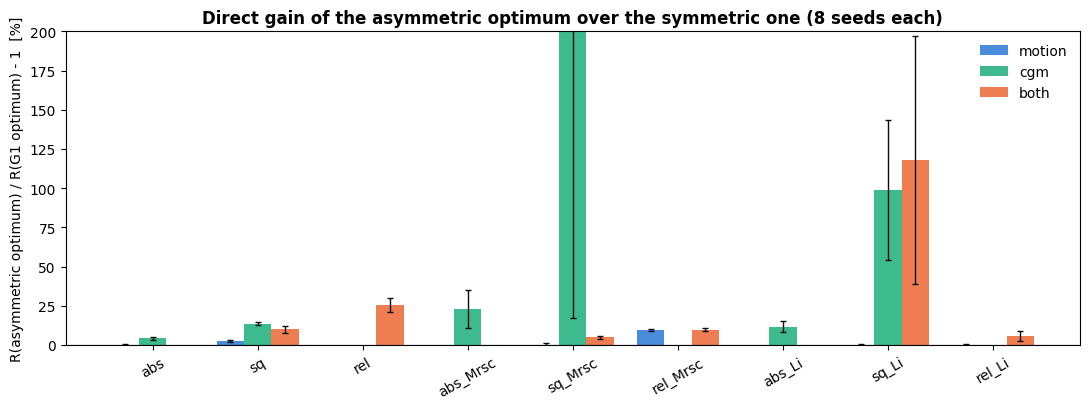

In [5]:
GAIN = {}      # GAIN[variant][key] = (gain, se)
CTRL = {}
print("Marasco's point, G1 against each asymmetric stag\ne"
      "(motion: the same model, so the control, must be 0 within 2 se; cgm, "
      "both: the effect of the CGM difference [and of v_motion = -40 in cgm]):")

for lab_ in ASYM:
    CTRL[lab_] = {k: ratio(rep_stat(STG["G1"], "marasco", k), rep_stat(STG[lab_], "marasco", k)) for k in KEYS}

print(f"{'residual':10s} " + " ".join(f"{v:>16s}" for v in ASYM))
for k in KEYS:
    print(f"{k:10s} " + " ".join(f"{100 * CTRL[v][k][0]:+8.2f} +-{100 * CTRL[v][k][1]:4.2f}%" for v in ASYM))

print("\nR at each residual's own optimum: asymmetric against G1  (negative = the asymmetric optimum is lower)")
print(f"{'residual':10s} {'R(G1 opt)':>12s} " + " " + " ".join(f"{v:^31s}" for v in ASYM))
for k in KEYS:
    a = rep_stat(STG["G1"], f"opt_{k}", k)
    row = f"{k:10s} {a[0]:10.5g} "
    for v in ASYM:
        b = rep_stat(STG[v], f"opt_{k}", k)
        gain, se = ratio(a, b); GAIN.setdefault(v, {})[k] = (gain, se)
        row += f"  {100 * gain:+8.2f} ±{100 * se:8.2f} % ({gain / S40[k]:+6.1f} u)"
    print(row)
print("\n(u = noise units of one run.)")

fig, ax = plt.subplots(figsize=(11, 4.2))
w = 0.26
for j, (v, col) in enumerate(zip(ASYM, ("#2a78d6", "#1baf7a", "#eb6834"))):
    y = np.array([100 * GAIN[v][k][0] for k in KEYS]); e = np.array([100 * GAIN[v][k][1] for k in KEYS])
    ax.bar(np.arange(len(KEYS)) + (j - 1) * w, y, w, yerr=e, 
           color=col, alpha=0.85, label=v, error_kw=dict(ecolor="#0b0b0b", lw=1, capsize=2))

ax.axhline(0, color="#0b0b0b", lw=0.8)
ax.set_xticks(range(len(KEYS)))
ax.set_xticklabels(KEYS, rotation=30)
ax.set_ylim(0, 200)
ax.set_ylabel("R(asymmetric optimum) / R(G1 optimum) - 1  [%]") 
ax.set_title("Direct gain of the asymmetric optimum over the symmetric one (8 seeds each)", weight="bold")
ax.legend(frameon=False)

plt.tight_layout()
plt.show()

### 2b. Where the gain sits

For one residual (we chose `abs_Li`), the replicates at its own optimum in G1 and in each asymmetric stage are compared **bin by bin**: north / south (the stored $R_N$, $R_S$ with the common flux scale), longitude (10° bins), $|b|$ bins and velocity bins. The difference is shown in units of its standard error (8 + 8 seeds): a bin matters only if it is beyond about 2.

motion  at opt_abs_Li: dR_N = +7.19 ± 0.23 %, dR_S = -11.31 ± 0.21 % of R(G1)
cgm     at opt_abs_Li: dR_N = +21.39 ± 4.73 %, dR_S = -9.66 ± 1.19 % of R(G1)
both    at opt_abs_Li: dR_N = +8.93 ± 0.41 %, dR_S = -12.85 ± 0.21 % of R(G1)


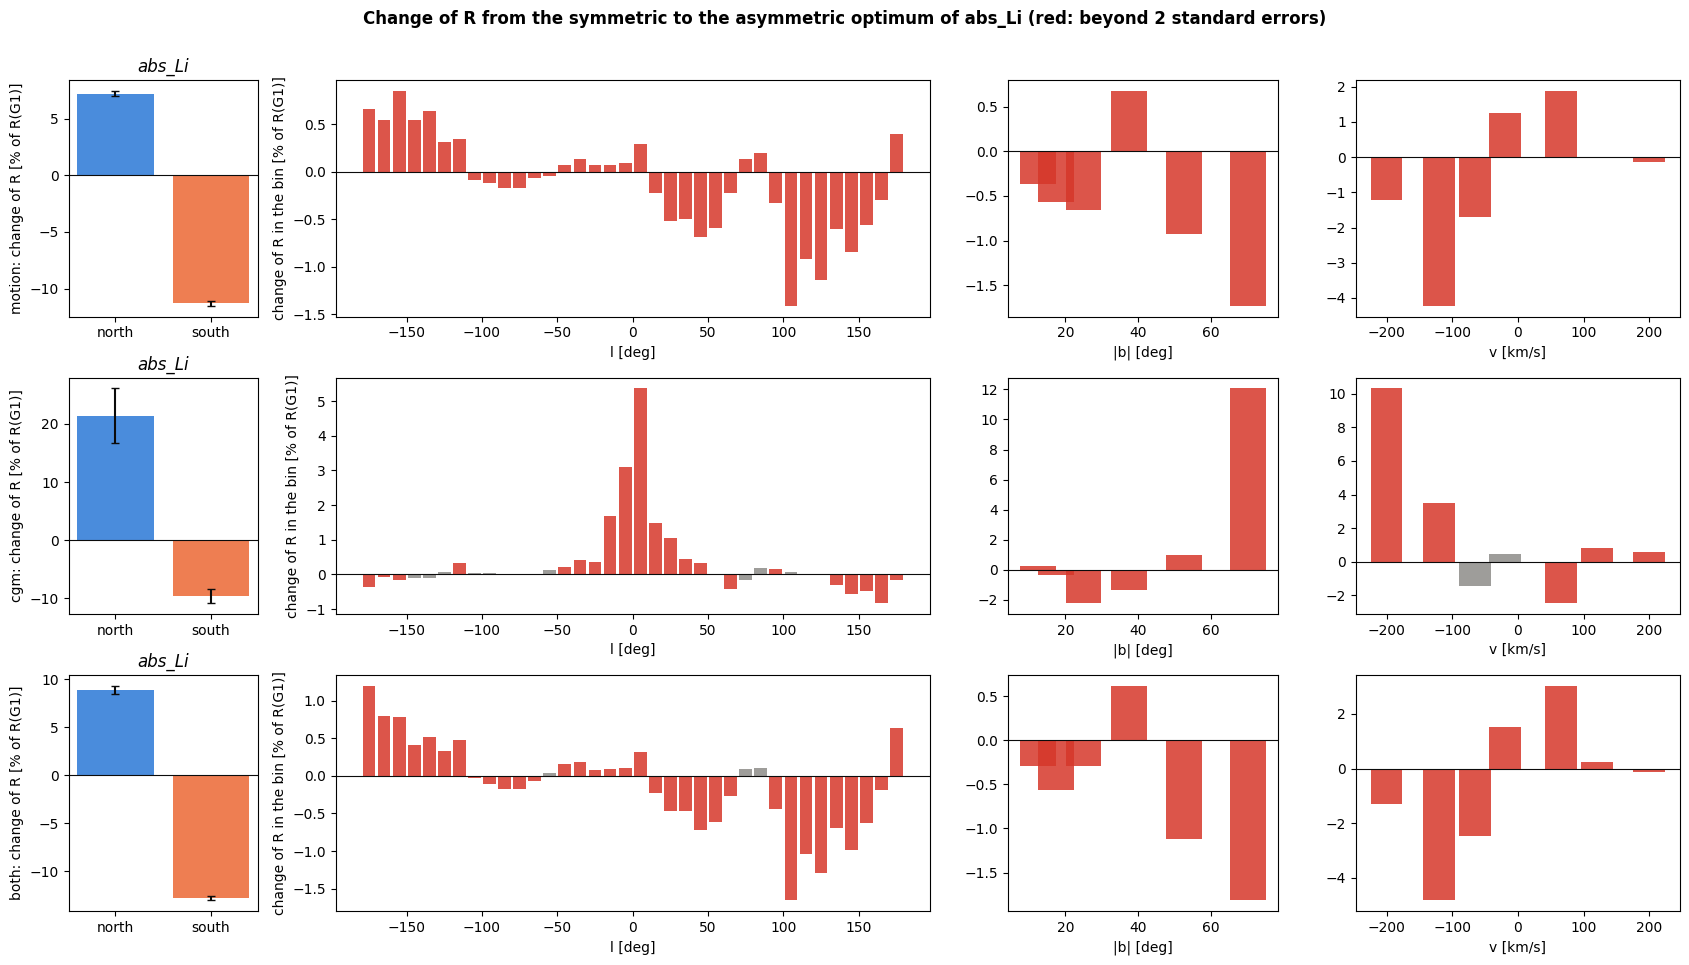

In [6]:
WHERE_KEY = "abs_Li"

def rep_array(T, place, field):
    names = T["REP"].get(place, [])
    return np.array([np.atleast_1d(T["RES"][n][field]) for n in names], float) if names else np.zeros((0, 1))

def diff_in_se(A, B):
    """ mean(B) - mean(A) per bin and its standard error. """
    d = B.mean(0) - A.mean(0)
    se = np.sqrt(A.var(0, ddof=1) / len(A) + B.var(0, ddof=1) / len(B))
    return d, se

place = f"opt_{WHERE_KEY}"
fig, axs = plt.subplots(len(ASYM), 4, figsize=(17, 3.2 * len(ASYM)), gridspec_kw=dict(width_ratios=[0.7, 2.2, 1, 1.2]))
l_ctr = 0.5 * (L_BINS[:-1] + L_BINS[1:])
b_ctr = 0.5 * (B_BINS[:-1] + B_BINS[1:])
v_ctr = 0.5 * (V_BINS[:-1] + V_BINS[1:])

for r, v in enumerate(ASYM):
    A, B = STG["G1"], STG[v]
    if place not in A["REP"] or place not in B["REP"]:
        for a in axs[r]: a.axis("off")
        axs[r, 0].text(0, 0.5, f"{v}: no replicates at {place}", transform=axs[r, 0].transAxes); continue
    tot = rep_stat(A, place, WHERE_KEY)[0]

    # North and south differences.
    dN, sN = diff_in_se(rep_array(A, place, f"R_{WHERE_KEY}_N"), rep_array(B, place, f"R_{WHERE_KEY}_N"))
    dS, sS = diff_in_se(rep_array(A, place, f"R_{WHERE_KEY}_S"), rep_array(B, place, f"R_{WHERE_KEY}_S"))

    axs[r, 0].bar([0, 1], [100 * dN[0] / tot, 100 * dS[0] / tot], 
                  yerr=[100 * sN[0] / tot, 100 * sS[0] / tot], 
                  color=["#2a78d6", "#eb6834"], alpha=0.85, error_kw=dict(ecolor="#0b0b0b", capsize=3))
    axs[r, 0].set_xticks([0, 1])
    axs[r, 0].set_xticklabels(["north", "south"])
    axs[r, 0].axhline(0, color="#0b0b0b", lw=0.8)
    axs[r, 0].set_ylabel(f"{v}: change of R [% of R(G1)]")
    axs[r, 0].set_title(f"{WHERE_KEY}", style="italic")
    
    for ax, field, ctr, name in ((axs[r, 1], f"by_l_{WHERE_KEY}", l_ctr, "l [deg]"), 
                                 (axs[r, 2], f"by_b_{WHERE_KEY}", b_ctr, "|b| [deg]"), 
                                 (axs[r, 3], f"by_v_{WHERE_KEY}", v_ctr, "v [km/s]")):
        
        d, s = diff_in_se(rep_array(A, place, field), rep_array(B, place, field))
        z = d / np.where(s > 0, s, np.nan)
        wd = np.diff(ctr).mean() * 0.85 if len(ctr) > 1 else 1
        ax.bar(ctr, 100 * d / tot, wd, color=np.where(np.abs(z) > 2, "#d6372a", "#8d8c88"), alpha=0.85)
        ax.axhline(0, color="#0b0b0b", lw=0.8); ax.set(xlabel=name)

        if name.startswith("l"):
            ax.set_ylabel("change of R in the bin [% of R(G1)]")

    print(f"{v:7s} at {place}: dR_N = {100 * dN[0] / tot:+4.2f} ± {100 * sN[0] / tot:4.2f} %, "
                             f"dR_S = {100 * dS[0] / tot:+4.2f} ± {100 * sS[0] / tot:4.2f} % of R(G1)")
    
fig.suptitle(f"Change of R from the symmetric to the asymmetric optimum of {WHERE_KEY} (red: beyond 2 standard errors)", 
             y=1.0, weight="bold")
plt.tight_layout()
plt.show()

## 3. The north-south budget

We know that LAB is not north-south symmetric. A model that is symmetric in $b$ cannot be right at both $+b$ and $-b$. For every pair of voxels $(+b, -b)$ with data and model in both, the best that any symmetric model can do is 

$$\min_M [f(D_N, M) + f(D_S, M)],$$

with $f$ being the term of the residual (a one-dimensional minimization per pair, done on a grid of candidate values $M$, for every key). Summed over the pairs this is the floor of the key.

Part of the floor is inevitably only noise. If the sky were exactly symmetric, the two noise draws would still differ. That part is estimated from a mock (the symmetric mean of the pair, plus fresh Gaussian noise of $\sigma$ on both sides) and subtracted.

The rest, we expect is the structural floor, the N-S difference of LAB itself. (The mock treats the noise of the two sides as independent; at $|b| \lesssim 8^\circ$ the beam makes it slightly correlated, which lowers the true noise part; the structural floor is then, if anything, underestimated.)

(The thresholded sets, `Mrsc` and `Li`, are defined for non-negative flux. Their minimization is over $M \ge 0$. The base set takes any $M$, as `ns_floor` does.)

The *share captured* is how much of the structural floor the asymmetric optimum removed relative to the symmetric optimum (section 2). For `abs` and `sq` of the base set the floor has a closed form (`floor_abs` $= \sum w |D_N - D_S|$ and `floor_sq` $= \frac12 \sum w (D_N - D_S)^2$, the `ns_floor` of `sigma_comp`).

In [7]:
def pair_arrays(vec):
    """ 
    The voxel pairs (+b, -b) that are valid in data and model on both sides (the selection of sigma_comp.ns_floor): 
    data N, data S, weight, model N, model S.
    """
    shape = cmp.lab_cmp.data.shape
    D = np.full(shape, np.nan); M = np.full(shape, np.nan)
    D[vec["valid"]] = vec["d"]; M[vec["valid"]] = vec["m"]

    b = np.asarray(cmp.b, float)
    iN = [i for i in range(len(b)) if b[i] > 0 and np.min(np.abs(b + b[i])) < 1e-6]
    iS = [int(np.argmin(np.abs(b + b[i]))) for i in iN]

    DN, DS, MN, MS = D[:, iN, :], D[:, iS, :], M[:, iN, :], M[:, iS, :]
    ok = np.isfinite(DN) & np.isfinite(DS) & np.isfinite(MN) & np.isfinite(MS)
    W = np.broadcast_to(np.asarray(cmp.w_b, float)[iN][None, :, None], DN.shape)

    return DN[ok], DS[ok], W[ok], MN[ok], MS[ok]

def pair_floor(dn, ds, w, n_cand=33):
    """
    Sum over the pairs of the minimum over a common M of f(D_N, M) + f(D_S, M), 
    for every key (candidates: between the two data values, their geometric mean, 0, and the thresholds; 
    M >= 0 for the thresholded sets, whose terms are not defined for negative flux).
    """
    lo, hi = np.minimum(dn, ds), np.maximum(dn, ds)
    thr = [set_threshold(s) for s in cmp.sets.values() if s.get("kind") == "select"]
    cands = [lo + (hi - lo) * t for t in np.linspace(0.0, 1.0, n_cand)] + \
            [np.zeros_like(lo), np.sqrt(np.clip(lo, 0.0, None) * np.clip(hi, 0.0, None))] + \
            [np.full_like(lo, T) for T in thr]

    # The keys of the 'base' set may take any M (as ns_floor), the thresholded sets only M >= 0.
    soft = np.array([cmp.sets[n].get("kind", "soft") == "soft" for n in cmp.sets for _ in OBS])
    best = None
    for Mc in cands:
        Mp = np.clip(Mc, 0.0, None)
        tot = np.where(soft[:, None], np.array(cmp._terms(dn, Mc, w)) + np.array(cmp._terms(ds, Mc, w)),
                                      np.array(cmp._terms(dn, Mp, w)) + np.array(cmp._terms(ds, Mp, w)))    # (n_keys, n_pairs)
        best = tot if best is None else np.minimum(best, tot)
    return best.sum(axis=1)

FIELDS = {}
FIELDS["G1"] = field_cubes("G1", best_model("G1"))
vec0 = FIELDS["G1"][4]["vec"]
dn, ds, ww, mn, ms = pair_arrays(vec0)
print(f"{len(dn)} voxel pairs with data and model at +b and -b (model: {best_model('G1')})")

fl = pair_floor(dn, ds, ww)
# No symmetric model can be below the floor: the symmetrised model of G1 is one of them.
msym = 0.5 * (mn + ms)
R_sym = np.array([x + y for x, y in zip(cmp._terms(dn, msym, ww), cmp._terms(ds, msym, ww))]).sum(axis=1)
bad = [k for k, f_, r_ in zip(KEYS, fl, R_sym) if f_ > r_ * (1 + 1e-3)]
if bad: print("WARNING: the floor is above the residual of a symmetric model for", bad, 
              "- the grid of candidate values missed the minimum there; read those floors as upper bounds")

cf_abs = float((ww * np.abs(dn - ds)).sum()); cf_sq = float((0.5 * ww * (dn - ds) ** 2).sum())
print(f"closed form / grid minimisation:  abs {cf_abs:.5g} / {fl[KEYS.index('abs')]:.5g},   "
      f"sq {cf_sq:.5g} / {fl[KEYS.index('sq')]:.5g}")

assert (abs(fl[KEYS.index("abs")] / cf_abs - 1) < 2e-3 and abs(fl[KEYS.index("sq")] / cf_sq - 1) < 2e-3
        ), "The generic floor does not reproduce the closed form."

try:
    from sigma_comp import ns_floor
    ref = ns_floor(vec0, cmp, SIGMA_NUM)
    print(f"sigma_comp.ns_floor:  floor_abs {ref['floor_abs']:.5g}, floor_sq {ref['floor_sq']:.5g}, "
          f"floor_noise {ref['floor_noise']:.5g}")
    
    assert (abs(ref["floor_abs"] / cf_abs - 1) < 1e-6 and abs(ref["floor_sq"] / cf_sq - 1) < 1e-6
            ), "ns_floor and this notebook use different voxels."
except ImportError:
    ref = None; print("sigma_comp not importable: the check against ns_floor is skipped.")

# The noise part: a symmetric sky (the mean of the pair, not below 0) plus noise on both sides.
rng = np.random.default_rng(11)
tm = np.clip(0.5 * (dn + ds), 0.0, None)
fl_noise = np.mean([pair_floor(tm + SIGMA_NUM * rng.standard_normal(tm.shape), 
                               tm + SIGMA_NUM * rng.standard_normal(tm.shape), ww) for _ in range(4)], axis=0)
FLOOR = dict(raw=dict(zip(KEYS, fl)), noise=dict(zip(KEYS, fl_noise)))

if ref:
    print(f"The noise part of the abs floor: mock {fl_noise[KEYS.index('abs')]:.5g}, "
          f"analytic (sqrt(2/pi) sqrt(2) sigma, ns_floor) {ref['floor_noise']:.5g}")
print()
print(f"{'residual':10s} {'floor':>10s} {'noise part':>11s} {'structural':>11s} | "
      f"{'R(G1 opt)':>10s} {'floor/R':>8s} {'structural/R':>13s} | {'pairs of the G1 model':>22s} {'/ floor':>8s}")

for i, k in enumerate(KEYS):
    Rg = rep_stat(STG["G1"], f"opt_{k}", k)[0]
    st = FLOOR["raw"][k] - FLOOR["noise"][k]
    print(f"{k:10s} {FLOOR['raw'][k]:10.5g} {FLOOR['noise'][k]:11.5g} {st:11.5g} | "
          f"{Rg:10.5g} {FLOOR['raw'][k] / Rg:8.1%} {st / Rg:13.1%} | {R_sym[i]:22.5g} {R_sym[i] / FLOOR['raw'][k]:8.2f}")
    
print("\n('pairs of the G1 model' = the residual of the symmetric model of G1 on the paired voxels only;\n"
      "its ratio to the floor shows how far a symmetric model is from the best a symmetric model could do.)")

71572 voxel pairs with data and model at +b and -b (model: P1_opt_abs_Li_s5)
closed form / grid minimisation:  abs 1276.2 / 1276.2,   sq 351.66 / 351.66
sigma_comp.ns_floor:  floor_abs 1276.2, floor_sq 351.66, floor_noise 175.02
The noise part of the abs floor: mock 174.45, analytic (sqrt(2/pi) sqrt(2) sigma, ns_floor) 175.02

residual        floor  noise part  structural |  R(G1 opt)  floor/R  structural/R |  pairs of the G1 model  / floor
abs            1276.2      174.45      1101.8 |     2927.8    43.6%         37.6% |                 2415.5     1.89
sq             351.66     0.48107      351.18 |     893.37    39.4%         39.3% |                 789.54     2.25
rel            6474.3        2917      3557.3 |      18097    35.8%         19.7% |                  16611     2.57
abs_Mrsc       977.75      18.241      959.51 |     2265.1    43.2%         42.4% |                 1849.7     1.89
sq_Mrsc        349.57    0.050142      349.52 |     895.17    39.1%         39.0% |        

In [8]:
print("Share of the structural north-south floor that the asymmetric optimum has captured (from section 2):\n")
print(f"{'residual':10s} {'structural floor':>17s} " + " " + " ".join(f"{v:^22s}" for v in ASYM))

CAPT = {}
for k in KEYS:
    st = FLOOR["raw"][k] - FLOOR["noise"][k]
    a = rep_stat(STG["G1"], f"opt_{k}", k)
    row = f"{k:10s} {st:17.5g} "

    for v in ASYM:
        b = rep_stat(STG[v], f"opt_{k}", k)
        dR = a[0] - b[0]; se = np.hypot(a[1], b[1])
        CAPT[(v, k)] = (dR / st, se / st)
        row += f"  {100 * dR / st:+7.1f} ±{100 * se / st:7.1f} %  "
    print(row)

print("\n(R is summed over all valid voxels and the floor only over the paired ones, about 90 % of the area:\n"
      "the share is therefore, if anything, slightly underestimated.)")

Share of the structural north-south floor that the asymmetric optimum has captured (from section 2):

residual    structural floor          motion                  cgm                    both         
abs                   1101.8      -0.8 ±    0.9 %      -11.0 ±    1.9 %       +4.6 ±    0.7 %  
sq                    351.18      -6.4 ±    2.1 %      -34.8 ±    2.0 %      -25.5 ±    5.9 %  
rel                   3557.3     +11.2 ±    1.5 %      +14.6 ±    0.9 %     -130.1 ±   23.1 %  
abs_Mrsc              959.51      +3.8 ±    1.1 %      -53.9 ±   28.8 %       +4.6 ±    1.1 %  
sq_Mrsc               349.52      -0.6 ±    2.3 %    -3089.7 ± 3046.3 %      -12.5 ±    2.5 %  
rel_Mrsc              2711.4     -32.8 ±    2.1 %      +26.4 ±    1.4 %      -32.8 ±    3.3 %  
abs_Li                1096.6     +10.8 ±    0.8 %      -30.8 ±    9.4 %      +10.3 ±    1.2 %  
sq_Li                 351.12      +0.5 ±    2.6 %     -253.6 ±  114.3 %     -303.0 ±  202.8 %  
rel_Li                6072.7   

## 4. The north halves as replicates, and what the south ratios do to the south

`M1` and `B1` use the same Sobol design (model $i$ of one has the parameters of model $i$ of the other), and the north run of the asymmetric model does not depend on the south ratios. So, the north-only residual of `M1_i` and of `B1_i` is the same function of the same parameters, measured twice with different seeds:

- the difference of their logarithms is pure run-to-run noise. Its scatter divided by $\sqrt{2}$ is the noise of one run of the **asymmetric** model, to be compared with the convergence study (made on the symmetric one);

- the south halves differ only by the three ratios: the mean difference over the design is the **effect of the CGM ratios on the south residual**, with no new run.

The hemisphere caches (`grid_resid_north_<TAG>.pkl`, `grid_resid_south_<TAG>.pkl`) of the two notebooks are read (section 6.1 of the grid-searcg notebooks). Each residual uses the flux scale of its own hemisphere.

In [9]:
def hemi(label, h):
    S = STG[label]; f = S["res"] / f"grid_resid_{h}_{TAG}.pkl"
    if not f.exists(): return None
    d = {n: r for n, r in pickle.load(open(f, "rb")).items() \
         if r.get("keys") == KEYS and S["RUNS"].get(n, {}).get("group") == S["stage"]}
    return d

HM = {(v, h): hemi(v, h) for v in ("motion", "both") for h in ("north", "south")}
have = all(HM[k] is not None for k in HM)
if not have:
    print("The hemisphere caches of M1 or B1 are missing: run section 6.1 of those notebooks first.")
else:
    # Pair the models of M1 and B1 by their index and check that the parameters are the same.
    PN = ("hv0", "alpha_conds", "alpha_hv", "f_ion", "v_motion")
    pairs = []
    for nm in HM[("motion", "north")]:
        i = nm.split("_", 1)[1]; nb_ = f"B1_{i}"
        if nb_ in HM[("both", "north")]: pairs.append((nm, nb_))
    for a, b_ in pairs:
        ra, rb = STG["motion"]["RUNS"][a]["kw"], STG["both"]["RUNS"][b_]["kw"]
        assert all(abs(ra[p] - rb[p]) < 1e-9 for p in PN), f"{a} and {b_} do not have the same parameters."

    print(f"{len(pairs)} pairs of models with identical parameters (M1_i, B1_i)\n")

    def lnR(label, h, key, idx): return np.array([np.log(HM[(label, h)][n]["R_" + key]) for n in idx])
    ia = [p[0] for p in pairs]; ib = [p[1] for p in pairs]
    def mad_sd(x): return 1.4826 * np.median(np.abs(x - np.median(x)))

    print(f"{'residual':10s} | {'north: mean(lnR_B-lnR_M)':>24s} {'noise/run (sd)':>15s} "
          f"{'(robust)':>9s} {'convergence':>12s} | {'south: mean effect of the ratios':>34s}")
    NS = {}
    for k in KEYS:
        dN = lnR("both", "north", k, ib) - lnR("motion", "north", k, ia)
        dS = lnR("both", "south", k, ib) - lnR("motion", "south", k, ia)
        NS[k] = dict(dN=dN, dS=dS)
        print(f"{k:10s} |  {100 * dN.mean():+15.2f} ±{100 * dN.std(ddof=1) / np.sqrt(len(dN)):5.2f} %  "
              f"{100 * dN.std(ddof=1) / np.sqrt(2):11.2f} % {100 * mad_sd(dN) / np.sqrt(2):7.2f} % {100 * S40[k]:10.2f} % | "
              f"{100 * dS.mean():+8.2f} ±{100 * dS.std(ddof=1) / np.sqrt(len(dS)):5.2f} %  "
              f"(sd over the design {100 * dS.std(ddof=1):.2f} %)")

    print()
    print("north: the mean must be 0 (same function); the noise per run is sd/sqrt(2)\n"
          "       (robust: from the median absolute deviation, which a few wild models do not inflate)\n"
          "       and should be near the convergence value.")
    print("south: a negative mean = the first-pass south ratios lower the south residual on average.")

512 pairs of models with identical parameters (M1_i, B1_i)

residual   | north: mean(lnR_B-lnR_M)  noise/run (sd)  (robust)  convergence |   south: mean effect of the ratios
abs        |            -0.24 ± 0.19 %         3.12 %    1.27 %       1.26 % |    +0.71 ± 0.15 %  (sd over the design 3.28 %)
sq         |            -0.80 ± 1.14 %        18.31 %    2.90 %       3.95 % |    +0.65 ± 1.07 %  (sd over the design 24.32 %)
rel        |            -0.03 ± 0.11 %         1.74 %    1.00 %       0.94 % |    +0.10 ± 0.06 %  (sd over the design 1.45 %)
abs_Mrsc   |            -0.27 ± 0.22 %         3.55 %    1.44 %       1.35 % |    +0.95 ± 0.20 %  (sd over the design 4.45 %)
sq_Mrsc    |            -0.80 ± 1.15 %        18.33 %    2.91 %       3.97 % |    +0.67 ± 1.08 %  (sd over the design 24.52 %)
rel_Mrsc   |            -0.05 ± 0.18 %         2.83 %    1.66 %       1.38 % |    -1.07 ± 0.12 %  (sd over the design 2.80 %)
abs_Li     |            -0.25 ± 0.20 %         3.17 %    1.31 %     

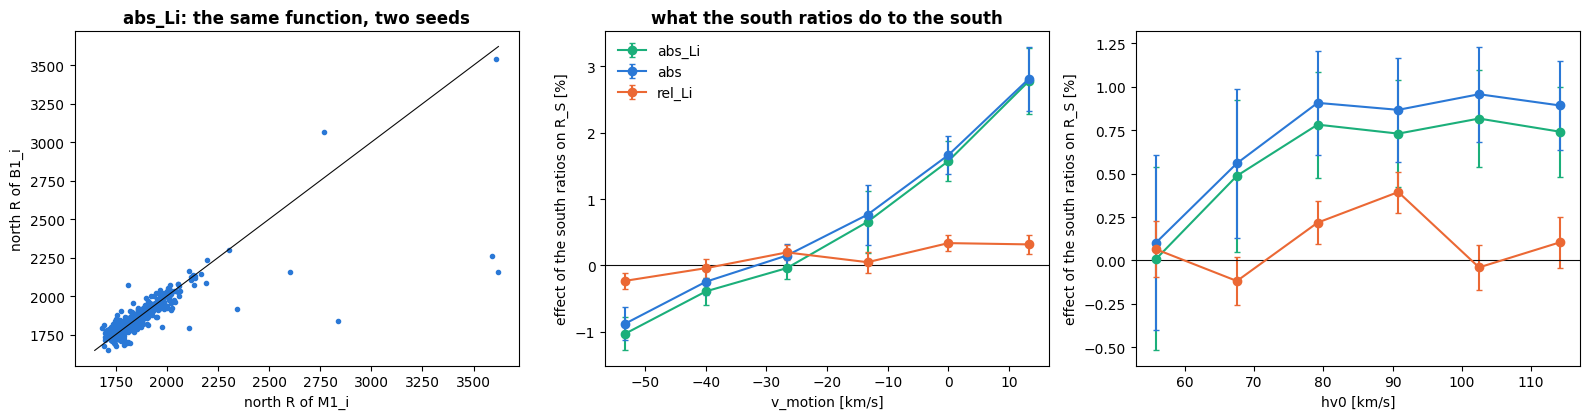

In [10]:
if have:
    fig, axs = plt.subplots(1, 3, figsize=(16, 4.3))
    k = "abs_Li"
    xa, xb = np.exp(lnR("motion", "north", k, ia)), np.exp(lnR("both", "north", k, ib))
    axs[0].plot(xa, xb, ".", color="#2a78d6")
    
    lim = [min(xa.min(), xb.min()), max(xa.max(), xb.max())]
    axs[0].plot(lim, lim, "-", color="#0b0b0b", lw=0.8)
    axs[0].set_xlabel("north R of M1_i")
    axs[0].set_ylabel("north R of B1_i")
    axs[0].set_title(f"{k}: the same function, two seeds", weight="bold")
    
    # The effect of the ratios on the south as a function of v_motion and hv0.
    th = np.array([[STG["both"]["RUNS"][n]["kw"][p] for p in PN] for n in ib])
    for ax, j, lab_ in ((axs[1], 4, "v_motion [km/s]"), (axs[2], 0, "hv0 [km/s]")):
        edges = np.quantile(th[:, j], np.linspace(0, 1, 7))
        idx = np.clip(np.digitize(th[:, j], edges[1:-1]), 0, 5)

        for kk, col in (("abs_Li", "#1baf7a"), ("abs", "#2a78d6"), ("rel_Li", "#eb6834")):
            d = NS[kk]["dS"]
            m = [100 * d[idx == q].mean() for q in range(6)]
            s = [100 * d[idx == q].std(ddof=1) / np.sqrt((idx == q).sum()) for q in range(6)]
            ax.errorbar(0.5 * (edges[:-1] + edges[1:]), m, s, fmt="o-", color=col, label=kk, capsize=2)
        ax.axhline(0, color="#0b0b0b", lw=0.8)
        ax.set(xlabel=lab_, ylabel="effect of the south ratios on R_S [%]")
        axs[1].legend(frameon=False)
    axs[1].set_title("what the south ratios do to the south", weight="bold")

    plt.tight_layout()
    plt.show()

**A pooled north-only fit.**

The two north halves are two independent measurements of one function, so they can be fitted together (1024 points instead of 512): a north-only optimum with half the run-to-run noise. If it differs from the two single fits by more than they differ from each other, the fits of one hemisphere are not reliable on their own.

Fit read from grid_fit_pooled_north_v35_L0_B0_f0.04_T0.04_k2_s3.12.pkl (3 residuals)
Fit read from grid_fit_north_M1only_v35_L0_B0_f0.04_T0.04_k2_s3.12.pkl (3 residuals)
Fit read from grid_fit_north_B1only_v35_L0_B0_f0.04_T0.04_k2_s3.12.pkl (3 residuals)

                                  M1 north           B1 north             pooled   M1 north - B1 north (sigma)
abs_Li     hv_pivot        62.695 +-11.458    69.856 +- 9.365    66.396 +-10.280       -0.5
           hv0             61.156 +- 9.759    69.695 +- 8.501    64.309 +-10.015       -0.7
           alpha_conds      7.133 +- 1.548     9.999 +- 0.028     9.999 +- 1.503       -1.9
           alpha_hv         0.022 +- 0.071     0.000 +- 0.001     0.004 +- 0.035       +0.3
           f_ion            0.249 +- 0.192     0.641 +- 0.119     0.364 +- 0.135       -1.7
           v_motion       -52.550 +-36.807    19.992 +- 4.330    12.727 +-22.306       -2.0

sq_Li      hv_pivot        56.128 +-24.076    76.691 +-11.221    78.737 +-12.591

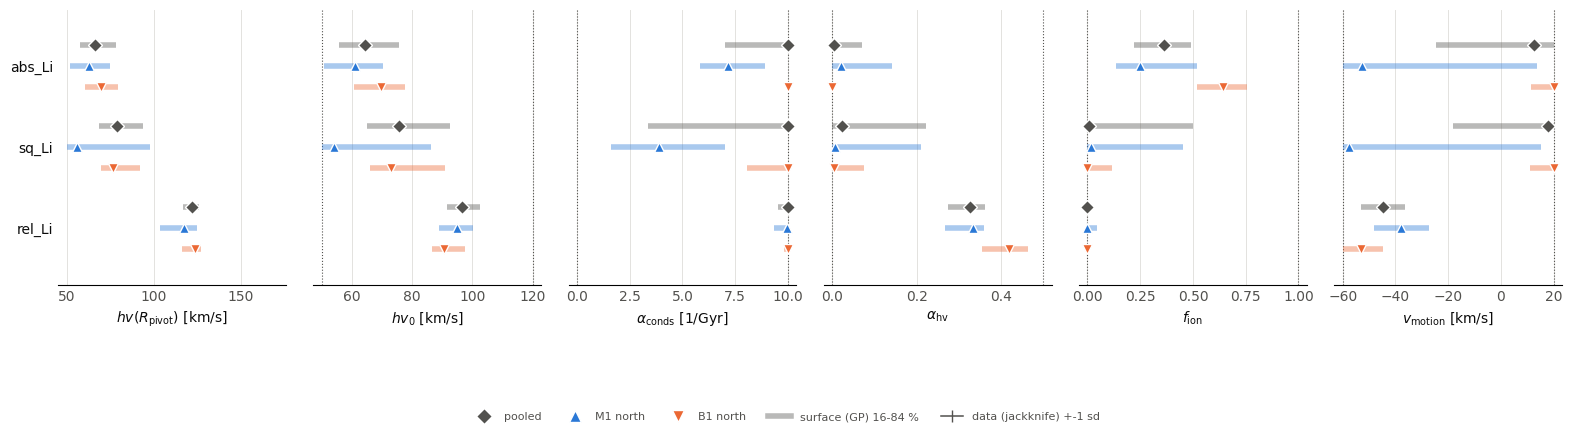

In [11]:
RUN_POOLED_NORTH = True
POOL_KEYS = ["abs_Li", "sq_Li", "rel_Li"]
if have and RUN_POOLED_NORTH:
    box = g.Box(names=PN, lo=(50.0, 0.0, 0.0, 0.0, V_MOTION_RANGE[0]), hi=(HV0_MAX, 10.0, 0.5, 1.0, V_MOTION_RANGE[1]))
    sfr = np.loadtxt(SFR_PROFILE) if Path(SFR_PROFILE).exists() else None
    feat = g.Features(box, sfrd=(lambda R: np.interp(np.asarray(R, float), sfr[:, 0], sfr[:, 1])) if sfr is not None else None)
    pool_res, pool_runs = {}, {}

    for v in ("motion", "both"):
        for n, r in HM[(v, "north")].items():
            pool_res[n] = r; pool_runs[n] = STG[v]["RUNS"][n]

    out_pool = gr.optima_cached(DIAG / f"grid_fit_pooled_north_{TAG}.pkl", pool_res, pool_runs, POOL_KEYS, NOISE, box, feat,
                                n_draws=200, n_restarts=4, jackknife=False)
    out_m = gr.optima_cached(DIAG / f"grid_fit_north_M1only_{TAG}.pkl", 
                             {n: HM[("motion", "north")][n] for n in ia}, 
                             {n: STG["motion"]["RUNS"][n] for n in ia},
                             POOL_KEYS, NOISE, box, feat, n_draws=200, n_restarts=4, jackknife=False)
    out_b = gr.optima_cached(DIAG / f"grid_fit_north_B1only_{TAG}.pkl", 
                             {n: HM[("both", "north")][n] for n in ib}, 
                             {n: STG["both"]["RUNS"][n] for n in ib},
                             POOL_KEYS, NOISE, box, feat, n_draws=200, n_restarts=4, jackknife=False)
    print()
    gr.print_comparison({"M1 north": out_m, "B1 north": out_b, "pooled": out_pool}, box, keys=POOL_KEYS)
    fig = gr.plot_optima_groups({"pooled": out_pool, "M1 north": out_m, "B1 north": out_b}, box, keys=POOL_KEYS, feat=feat)
    plt.show()
else:
    print("skipped")

## 5. Stage `PR1`: the south ratios one at a time

Section 4 gives the effect of the three first-pass ratios **together**. This stage separates them, and adds a much hotter southern corona. Oprea et al. (2026) report $\Delta T/T \approx 12$ % for the density-weighted average inside a cone (13-20 % in the simulation, depending on its truncation) but a southern temperature of $4-6 \times 10^6$ K against $2.5 \times 10^6$ K in the north near the disc inside the solar circle, where the clouds fly: a ratio of 1.6 and more. The first-pass `T_RATIO = 1.12` may be too small by a large factor where it matters.

All places are at the `abs_Li` optimum of the `B1` fit (`hv0`, `alpha_conds`, `alpha_hv`, `f_ion`, `v_motion`), 8 seeds each, $n = 40$; only the south ratios and (in the last two places) `v_motion` change:

| place | `south_vlag_ratio` | `south_alpha_conds_ratio` | `south_drag_ratio` | `v_motion` |
|---|---|---|---|---|
| `ratios1` | 1 | 1 | 1 | optimum |
| `vlag_only` | 1.12 | 1 | 1 | optimum |
| `cond_only` | 1 | 1.185 | 1 | optimum |
| `drag_only` | 1 | 1 | 1.185 | optimum |
| `all` | 1.12 | 1.185 | 1.185 | optimum (= the fit of `B1`) |
| `hot` | 1.6 | 2.02 | 2.02 | optimum ($T$ ratio 1.6, density $\propto T^{3/2}$) |
| `all_vm40` | 1.12 | 1.185 | 1.185 | $-40$ |
| `all_vm0` | 1.12 | 1.185 | 1.185 | 0 |

`PR1` is evaluated and compared in the cell after the job, with the same replicate machinery as `P1`.

In [12]:
PR1_STAGE, PR1_N, PR1_SEEDS, PR1_SEED0 = "PR1", 40, 8, 25000       # seeds 25000 ... 25063 (check: no stage uses them)
PR1_WRITE = True
RUNS_DIR = WORK / "runs"; PR1_FILE = RUNS_DIR / f"grid4d_{PR1_STAGE}.json"

fitB = pickle.load(open(ASYM["both"]["res"] / f"grid_fit_{TAG}.pkl", "rb"))["out"] \
    if (ASYM["both"]["res"] / f"grid_fit_{TAG}.pkl").exists() else None

if fitB is None:
    print("the fit of B1 is not stored: run the B1 notebook up to step 5 first")
else:
    th0 = np.asarray(fitB["abs_Li"]["est"]["theta_mean_opt"], float) # hv0, alpha_conds, alpha_hv, f_ion, v_motion
    names_fit = ["hv0", "alpha_conds", "alpha_hv", "f_ion", "v_motion"]
    names_rat = ["south_vlag_ratio", "south_alpha_conds_ratio", "south_drag_ratio"]

    def place(vl=1.0, ac=1.0, dr=1.0, vm=None):
        th = th0.copy()
        if vm is not None: th[4] = vm
        return np.concatenate([th, [vl, ac, dr]])
    
    HOT = 1.6 # A much hotter south: T ratio 1.6, density ~ T^(3/2) (the adiabatic mapping of the first pass).
    PR1_POINTS = {"ratios1": place(), 
                  "vlag_only": place(vl=T_RATIO), 
                  "cond_only": place(ac=RHO_RATIO), 
                  "drag_only": place(dr=RHO_RATIO),
                  "all": place(T_RATIO, RHO_RATIO, RHO_RATIO), 
                  "hot": place(HOT, HOT ** 1.5, HOT ** 1.5),
                  "all_vm40": place(T_RATIO, RHO_RATIO, RHO_RATIO, vm=-40.0), 
                  "all_vm0": place(T_RATIO, RHO_RATIO, RHO_RATIO, vm=0.0)}
    
    FIXED1 = gr.fixed_from_run_conv(varied=tuple(names_fit + names_rat)); FIXED1.update(v_kick=0.0)

    if PR1_FILE.exists():
        PR1_RUNS = g.load_runs(PR1_FILE); print(f"{PR1_FILE.name} exists: loaded, not regenerated.")
    elif PR1_WRITE:
        PR1_RUNS = gr.design_replicates(PR1_POINTS, PR1_STAGE, PR1_N, PR1_SEEDS, PR1_SEED0, names_fit + names_rat, FIXED1)
        clash = gr.seeds_used_elsewhere(RUNS_DIR, PR1_STAGE) & {r["seed"] for r in PR1_RUNS.values()}
        assert not clash, f"Seeds already used by another stage: {sorted(clash)[:5]}."
        print("Run file:", g.save_runs(PR1_RUNS, PR1_FILE))
    else:
        PR1_RUNS = None; print("PR1_WRITE = False: nothing written.")
        
    if PR1_RUNS:
        print(f"\n{len(PR1_RUNS)} runs = {len(PR1_POINTS)} places x {PR1_SEEDS} seeds\n")
        print(f"{'place':10s} " + " ".join(f"{n:>11s}" for n in ("hv0", "alpha_conds", "alpha_hv", 
                                                                 "f_ion", "v_motion", "vlag_r", "cond_r", "drag_r")))
        
        for lab_, th in PR1_POINTS.items():
            print(f"{lab_:10s} " + " ".join(f"{x:11.3f}" for x in th))

        est = gr.job_estimate(PR1_RUNS, PROBE_MIN, PROBE_MB, workers=len(PR1_RUNS), n_probe=PROBE_N, slow=1.0)
        gr.memory_advice(est, current_gb=256)
        print(f"\nOn heron, in mw_grid.sub set   STAGE = {PR1_STAGE}   and   NWORK = {len(PR1_RUNS)}   "
              f"(one worker per run), then condor_submit as for the other check stages.")

grid4d_PR1.json exists: loaded, not regenerated.

64 runs = 8 places x 8 seeds

place              hv0 alpha_conds    alpha_hv       f_ion    v_motion      vlag_r      cond_r      drag_r
ratios1         67.623       7.289       0.050       0.000     -52.837       1.000       1.000       1.000
vlag_only       67.623       7.289       0.050       0.000     -52.837       1.120       1.000       1.000
cond_only       67.623       7.289       0.050       0.000     -52.837       1.000       1.185       1.000
drag_only       67.623       7.289       0.050       0.000     -52.837       1.000       1.000       1.185
all             67.623       7.289       0.050       0.000     -52.837       1.120       1.185       1.185
hot             67.623       7.289       0.050       0.000     -52.837       1.600       2.024       2.024
all_vm40        67.623       7.289       0.050       0.000     -40.000       1.120       1.185       1.185
all_vm0         67.623       7.289       0.050       0.000      

**After the `PR1` job.** 

The pack is evaluated (cache in `results_PR1`), and every place is compared with `ratios1` (all south ratios equal to 1 at the same parameters). One noise unit is about 1.3 % of $R$ for one run; eight seeds give about 0.5 % per place, so the table sees differences of about 1.5 % and more.

In [13]:
PR1_PACKS = sorted(WORK.glob(f"out_{PR1_STAGE}_*/pack.fits"))
if not PR1_PACKS:
    print("No pack of PR1 yet: run the job and copy the pack (the commands are printed above), then run this cell again.")
else:
    RES_DIR_PR = WORK / f"results_{PR1_STAGE}"; RES_DIR_PR.mkdir(exist_ok=True)
    pack_pr = gr.open_packs(PR1_PACKS, RES_DIR_PR / "grid_all.fits")
    RES_PR = gr.evaluate_pack(pack_pr, cmp, cache=RES_DIR_PR / f"grid_resid_{TAG}.pkl", workers=WORKERS)
    STG["PR1"] = dict(label="PR1", stage=PR1_STAGE, check=PR1_STAGE, RES=RES_PR, RUNS=pack_pr.runs())
    STG["PR1"]["REP"] = rep_groups(RES_PR, PR1_STAGE)
    places_ = ["vlag_only", "cond_only", "drag_only", "all", "hot", "all_vm40", "all_vm0"]
    print(f"R of every place against 'ratios1' (same parameters, no south difference); ±: standard error of the two means\n")
    print(f"{'residual':11s} " + " ".join(f"{p:<15s}" for p in places_))

    for k in KEYS:
        a = rep_stat(STG["PR1"], "ratios1", k)
        print(f"{k:10s} " + " ".join("{:+6.2f}±{:4.2f}%   ".format(*(100 * x for x in ratio(a, rep_stat(STG['PR1'], p, k))
                                                                     )) for p in places_))
    
    print("\nNorth and south separately for abs_Li (the first five places differ from 'ratios1' only in the south ratios,\n"
          "so there the north is a noise check; the last two also change v_motion, which moves both halves):")
    
    for h in ("N", "S"):
        a = rep_stat(STG["PR1"], "ratios1", "abs_Li", field=lambda k, h=h: f"R_{k}_{h}")
        print(f"> {h}: " + "  ".join(f"{p} {100 * ratio(a, rep_stat(STG['PR1'], p, 'abs_Li', 
                                                                    field=lambda k, 
                                                                    h=h: f'R_{k}_{h}'))[0]:+.2f}%" for p in places_))

0 new evaluations in 0 s; 64 models evaluated
R of every place against 'ratios1' (same parameters, no south difference); ±: standard error of the two means

residual    vlag_only       cond_only       drag_only       all             hot             all_vm40        all_vm0        
abs         -0.25±0.39%     +0.28±0.37%     +0.72±0.37%     -0.24±0.40%     -1.81±0.35%     -0.17±0.47%     +7.22±0.40%   
sq          -0.33±1.01%     +0.36±0.99%     +1.87±0.95%     -0.87±1.10%     -6.11±0.81%     -5.77±1.23%     +6.92±1.10%   
rel         -0.13±0.28%     +0.55±0.28%     +0.40±0.28%     +0.13±0.30%     -0.77±0.26%     +1.19±0.31%     +3.82±0.30%   
abs_Mrsc    -0.37±0.52%     +0.10±0.45%     +0.89±0.44%     -0.41±0.51%     -2.29±0.42%     -0.14±0.59%     +9.67±0.49%   
sq_Mrsc     -0.33±1.02%     +0.35±1.00%     +1.89±0.96%     -0.88±1.11%     -6.16±0.81%     -5.82±1.24%     +6.99±1.11%   
rel_Mrsc    -0.47±0.50%     -0.56±0.57%     +0.40±0.40%     -0.44±0.60%     -1.05±0.38%     +3.60±0.54% 

## 6. A flux-scale difference between the hemispheres

Every grid-search residual uses **one** flux scale for the whole sky ($\sum w D / \sum w M$ over all compared voxels): the model's absolute brightness is Marasco+12's SFR and a fixed gas-to-flux conversion, and the scale only absorbs the part of it we do not trust. If the south of the real Galaxy simply has less (or more) extended gas than the north, as a quenching or an SFR asymmetry would give, a symmetric-in-normalization model will try to make up the difference with the wind, which changes the number of clouds that reach a given height.

Therefore, we do a cheap test. We give each hemisphere its own scale ($R_N$ and $R_S$ with $\sum w D / \sum w M$ taken over that hemisphere only, as in the hemisphere caches), and see what is left of the wind's gain. At the replicates (8 seeds each, at the joint-scale optimum of each residual, for `G1` and for the asymmetric stages) both are evaluated with the same model. The ratio $s_S / s_N$ is the *normalization asymmetry the model wants*: a value far from 1 at the best models is a result in itself.

(A symmetric model with two free scales is still symmetric in everything else: the scale only multiplies the whole hemisphere, it does not move gas in height, so it cannot mimic the wind except through the normalization of the high-latitude gas.)

In [14]:
import warnings

def hemi_eval_fn(mirror=False):
    """ Evaluator for `evaluate_pack`, one pass over the model:
          scale, R_<key>                        the whole sky with ONE flux scale (the grid searches),
          scale_N, scale_S, R_<key>_N2, _S2     each hemisphere with its OWN scale (as the hemisphere caches),
          R_<key>_N, _S                         the two halves of the one-scale R,
          D_N, D_S, M_N, M_S                    the weighted sums of LAB and of the unscaled model per hemisphere 
                                                    (scale_h = D_h / M_h),
          nv_N, nv_S                            the voxels compared.

        mirror = True keeps a voxel only if its mirror image (same l and v, b -> -b) is also compared 
        (valid in the data AND in the model): every one-sided mask (Outer Arm, GC pole, external galaxies, Magellanic system) 
        is then made symmetric in b.
    """

    def fn(cmp_, mod):
        obs, mdl = cmp_.lab_cmp.data, mod.data; shp = obs.shape
        b = np.asarray(cmp_.b, float)
        bb = np.broadcast_to(b[None, :, None], shp)
        ok = np.isfinite(obs) & np.isfinite(mdl) & (bb != 0)

        if mirror:
            jm = np.argmin(np.abs(b[:, None] + b[None, :]), axis=1) # index of -b
            ok = ok & ok[:, jm, :]

        w = np.broadcast_to(np.asarray(cmp_.w_b, float)[None, :, None], shp)
        o, m_, ww = obs[ok].astype(float), mdl[ok].astype(float), w[ok]
        s = (ww * o).sum() / (ww * m_).sum()
        out = {"keys": list(cmp_.keys), "scale": float(s), "n_valid": int(ok.sum())}

        for k, t in zip(cmp_.keys, cmp_._terms(o, s * m_, ww)): 
            out["R_" + k] = float(t.sum())

        for h, sel in (("N", bb > 0), ("S", bb < 0)):
            sl = ok & sel
            oh, mh, wh = obs[sl].astype(float), mdl[sl].astype(float), w[sl]
            sh = (wh * oh).sum() / (wh * mh).sum()
            out.update({"scale_" + h: float(sh), 
                        "D_" + h: float((wh * oh).sum()), 
                        "M_" + h: float((wh * mh).sum()), 
                        "nv_" + h: int(sl.sum())})
            
            for k, t in zip(cmp_.keys, cmp_._terms(oh, sh * mh, wh)): 
                out["R_" + k + "_" + h + "2"] = float(t.sum())

            for k, t in zip(cmp_.keys, cmp_._terms(oh, s * mh, wh)): 
                out["R_" + k + "_" + h] = float(t.sum())

        return out
    return fn

two_scale_fn = lambda: hemi_eval_fn(False) # (the name of the first version of this notebook)

B_PLACES = ["marasco"] + [f"opt_{k}" for k in ("abs_Li", "abs", "rel_Li")]
B_LABELS = ["G1", "motion", "both"]
RES2 = {}

for lab_ in B_LABELS:
    T = STG[lab_]; names = sorted({n for p in B_PLACES for n in T["REP"].get(p, [])})

    if not names: 
        print(f"{lab_}: no replicates.")
        continue

    RES2[lab_] = gr.evaluate_pack(get_pack(lab_), cmp, names=names, 
                                  cache=DIAG / f"resid_hemi_{lab_}_{TAG}.pkl", workers=WORKERS, fn=hemi_eval_fn(False))

def two_scale_stat(label, place, key):
    names = [n for n in STG[label]["REP"].get(place, []) if n in RES2.get(label, {})]
    joint = np.array([STG[label]["RES"][n]["R_" + key] for n in names])
    two = np.array([RES2[label][n]["R_" + key + "_N2"] + RES2[label][n]["R_" + key + "_S2"] for n in names])
    sr = np.array([RES2[label][n]["scale_S"] / RES2[label][n]["scale_N"] for n in names])

    return joint, two, sr

def mse(x): return x.mean(), (x.std(ddof=1) / np.sqrt(len(x)) if len(x) > 1 else np.nan)

print()
print("s_S / s_N of the flux scale (south over north), at each stage's replicates of "
      "Marasco's point and of each residual's own optimum:")
print(f"{'place':12s} " + " ".join(f"{l_:>16s}" for l_ in B_LABELS))
for p in B_PLACES:
    row = f"{p:12s} "
    for lab_ in B_LABELS:
        sr = two_scale_stat(lab_, p, KEYS[0])[2] if lab_ in RES2 else np.array([])
        row += f"{'' if len(sr) == 0 else '%7.3f +-%5.3f' % mse(sr):>16s} "
    print(row)

print("\nR with one common scale (the grid searches) and with one scale per hemisphere, "
      "at each residual's own joint-scale optimum:")
print(f"{'residual':10s} " + " ".join(f"{l_ + ': joint | 2 scales | gain':>40s}" for l_ in B_LABELS))
TWO = {}
for k in ("abs_Li", "abs", "rel_Li", "sq_Li", "rel"):
    row = f"{k:10s} "
    for lab_ in B_LABELS:
        if lab_ not in RES2: row += f"{'':>40s} "; continue
        j, t, _ = two_scale_stat(lab_, f"opt_{k}", k) if f"opt_{k}" in STG[lab_]["REP"] else (np.array([np.nan]), np.array([np.nan]), None)
        TWO[(lab_, k)] = (j, t)
        gj = mse(t / j - 1.0)
        row += f"{j.mean():10.5g} | {t.mean():10.5g} | {100 * gj[0]:+6.2f} +-{100 * gj[1]:4.2f}%    "
    print(row)

print("\nThe asymmetric stage against G1, with ONE scale and with TWO scales "
      "(at the joint-scale optima; negative = the asymmetric model is lower):")
print(f"{'residual':10s} " + " ".join(f"{l_ + ': one scale | two scales':>40s}" for l_ in B_LABELS[1:]))

with warnings.catch_warnings():
    for k in ("abs_Li", "abs", "rel_Li", "sq_Li", "rel"):
        row = f"{k:10s} "
        for lab_ in B_LABELS[1:]:
            if (lab_, k) not in TWO or ("G1", k) not in TWO: 
                row += f"{'':>40s} "
                continue
            a1, a2 = (mse(TWO[("G1", k)][0]), mse(TWO[("G1", k)][1]))
            b1, b2 = (mse(TWO[(lab_, k)][0]), mse(TWO[(lab_, k)][1]))
            g1, g2 = ratio((a1[0], a1[1], 8), (b1[0], b1[1], 8)), ratio((a2[0], a2[1], 8), (b2[0], b2[1], 8))
            
            row += f"{100 * g1[0]:+7.2f} +-{100 * g1[1]:4.2f}% | {100 * g2[0]:+7.2f} +-{100 * g2[1]:4.2f}%      "
        print(row)

0 new evaluations in 0 s; 32 models evaluated
0 new evaluations in 0 s; 32 models evaluated
0 new evaluations in 0 s; 32 models evaluated

s_S / s_N of the flux scale (south over north), at each stage's replicates of Marasco's point and of each residual's own optimum:
place                      G1           motion             both
marasco         0.567 +-0.002    0.566 +-0.003    0.454 +-0.013 
opt_abs_Li      0.558 +-0.001    1.248 +-0.010    1.406 +-0.012 
opt_abs         0.560 +-0.001    0.914 +-0.004    1.389 +-0.013 
opt_rel_Li      0.491 +-0.002    0.868 +-0.003   13.065 +-7.057 

R with one common scale (the grid searches) and with one scale per hemisphere, at each residual's own joint-scale optimum:
residual                G1: joint | 2 scales | gain          motion: joint | 2 scales | gain            both: joint | 2 scales | gain
abs_Li         2882.9 |     2831.5 |  -1.78 +-0.03%        2764.2 |     2769.3 |  +0.18 +-0.02%        2769.8 |     2770.5 |  +0.03 +-0.07%    
abs  

/tmp/ipykernel_13305/258832395.py:77: RuntimeWarning: Mean of empty slice.
  def mse(x): return x.mean(), (x.std(ddof=1) / np.sqrt(len(x)) if len(x) > 1 else np.nan)
<redacted_for_privacy>/site-packages/numpy/_core/_methods.py:144: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/tmp/ipykernel_13305/258832395.py:101: RuntimeWarning: Mean of empty slice.
  row += f"{j.mean():10.5g} | {t.mean():10.5g} | {100 * gj[0]:+6.2f} +-{100 * gj[1]:4.2f}%    "
/tmp/ipykernel_13305/258832395.py:77: RuntimeWarning: Mean of empty slice.
  def mse(x): return x.mean(), (x.std(ddof=1) / np.sqrt(len(x)) if len(x) > 1 else np.nan)
<redacted_for_privacy>/site-packages/numpy/_core/_methods.py:144: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


In [15]:
# Where does s_S / s_N come from?  
# s_h = D_h / M_h (weighted LAB sum over the compared voxels of the hemisphere / weighted sum of the unscaled model),
# so  s_S / s_N = (D_S / D_N) / (M_S / M_N):  the first factor is a property of LAB and of the masks, 
# the second is the model's own north/south flux ratio.

def dm_stat(label, place):
    names = [n for n in STG[label]["REP"].get(place, []) if n in RES2.get(label, {})]
    if not names: return None
    r = [RES2[label][n] for n in names]
    return {k: np.array([x[k] for x in r], float) for k in ("D_N", "D_S", "M_N", "M_S", "nv_N", "nv_S", "scale_N", "scale_S")}

print("s_S/s_N = (D_S/D_N) / (M_S/M_N), at the replicates of each place "
      "(mean over the seeds; D = LAB, M = model, both summed with the weights over the compared voxels of the hemisphere):\n")
print(f"{'stage':7s} {'place':11s} {'s_S/s_N':>8s} {'D_S/D_N':>8s} {'M_S/M_N':>8s} {'voxels S/N':>11s}")

for lab_ in B_LABELS:
    for p in B_PLACES:
        d_ = dm_stat(lab_, p)
        if d_ is None: continue
        print(f"{lab_:7s} {p:11s} {np.mean(d_['scale_S'] / d_['scale_N']):8.3f} {np.mean(d_['D_S'] / d_['D_N']):8.3f} "
              f"{np.mean(d_['M_S'] / d_['M_N']):8.3f} {np.mean(d_['nv_S']) / np.mean(d_['nv_N']):11.3f}")
        
print("\nD_S/D_N does not depend on the model (only on which voxels are compared).\n"
      "M_S/M_N is the north-south ratio of the model's flux.\nA symmetric model (G1) has M_S/M_N = 1 "
      "on the voxels both hemispheres share,\nso what moves it away from 1 there is the masks\n"
      "(one-sided: Outer Arm, GC pole, external galaxies, Magellanic system) and, in the asymmetric stages, the wind.")

s_S/s_N = (D_S/D_N) / (M_S/M_N), at the replicates of each place (mean over the seeds; D = LAB, M = model, both summed with the weights over the compared voxels of the hemisphere):

stage   place        s_S/s_N  D_S/D_N  M_S/M_N  voxels S/N
G1      marasco        0.567    0.661    1.166       0.887
G1      opt_abs_Li     0.558    0.661    1.183       0.887
G1      opt_abs        0.560    0.661    1.180       0.887
G1      opt_rel_Li     0.491    0.661    1.347       0.887
motion  marasco        0.566    0.661    1.167       0.887
motion  opt_abs_Li     1.248    0.661    0.529       0.887
motion  opt_abs        0.914    0.661    0.723       0.887
motion  opt_rel_Li     0.868    0.661    0.761       0.887
both    marasco        0.454    0.661    1.466       0.887
both    opt_abs_Li     1.406    0.661    0.470       0.887
both    opt_abs        1.389    0.661    0.476       0.887
both    opt_rel_Li    13.065    0.661    0.101       0.887

D_S/D_N does not depend on the model (only on whic

### 6b. Across the grid

The hemisphere caches give $s_N$ and $s_S$ of every grid model (the `scale` of the north-only and south-only evaluations): if the south wants a different normalization, $\ln (s_S/s_N)$ among the *good* models is not zero, and in `M1` it may move with $v_{\rm motion}$ (the wind and the normalization trading). 

The second part fits the sum $R_N + R_S$ with own scales as a residual in its own right (a surface fit as in the grid searches, no new model) and compares its optimum with the one-scale optimum.

G1     : ln(s_S/s_N) over the grid: median -0.595, sd 0.076; best 5 % of R_N + R_S (abs_Li): -0.603 ± 0.006  (s_S/s_N = 0.547)
motion : ln(s_S/s_N) over the grid: median -0.389, sd 0.737; best 5 % of R_N + R_S (abs_Li): -0.289 ± 0.087  (s_S/s_N = 0.749)
both   : ln(s_S/s_N) over the grid: median -0.452, sd 0.587; best 5 % of R_N + R_S (abs_Li): -0.279 ± 0.087  (s_S/s_N = 0.757)


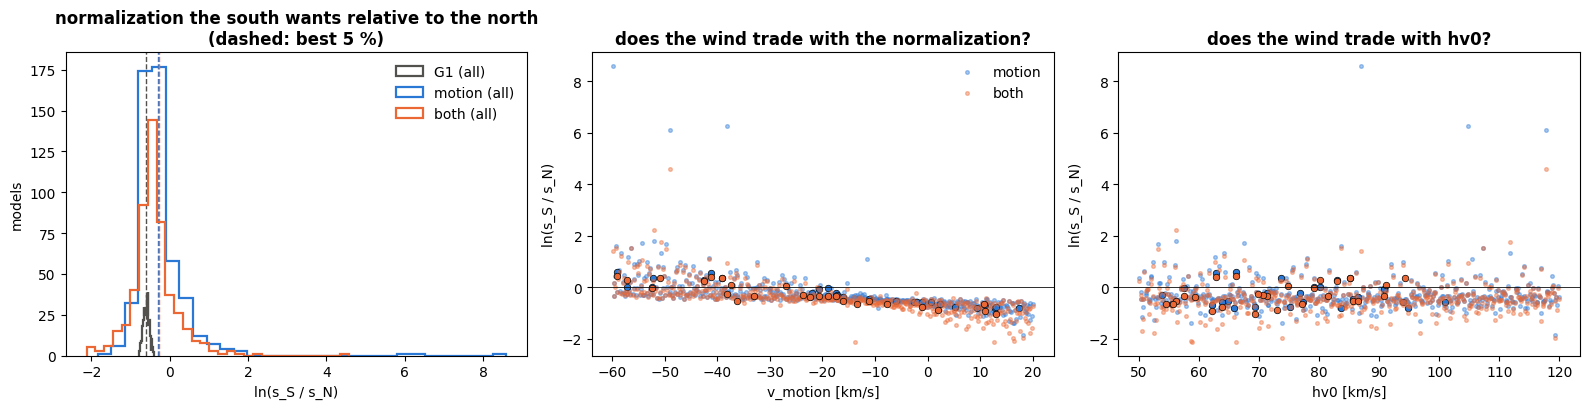

In [16]:
def scale_arrays(label):
    N, S = hemi(label, "north"), hemi(label, "south")
    if N is None or S is None: return None
    names = [n for n in N if n in S]
    return names, np.array([N[n]["scale"] for n in names]), np.array([S[n]["scale"] for n in names]), N, S

fig, axs = plt.subplots(1, 3, figsize=(16, 4.2))
for lab_, col in (("G1", "#52514e"), ("motion", "#2a78d6"), ("both", "#eb6834")):
    sa = scale_arrays(lab_)

    if sa is None: 
        print(f"{lab_}: no hemisphere caches"); continue
    names, sN, sS, N, S = sa

    R2 = np.array([N[n]["R_abs_Li"] + S[n]["R_abs_Li"] for n in names])
    good = R2 <= np.sort(R2)[max(9, len(R2) // 20)]    # best 5 % (at least 10)
    lr = np.log(sS / sN)

    print(f"{lab_:7s}: ln(s_S/s_N) over the grid: median {np.median(lr):+.3f}, sd {lr.std():.3f}; "
          f"best 5 % of R_N + R_S (abs_Li): {lr[good].mean():+.3f} ± {lr[good].std(ddof=1) / np.sqrt(good.sum()):.3f}  "
          f"(s_S/s_N = {np.exp(lr[good].mean()):.3f})")
    
    axs[0].hist(lr, bins=30, histtype="step", color=col, lw=1.6, label=f"{lab_} (all)")
    axs[0].axvline(lr[good].mean(), color=col, ls="--", lw=1)

    if lab_ != "G1":
        v = np.array([STG[lab_]["RUNS"][n]["kw"]["v_motion"] for n in names])
        axs[1].scatter(v, lr, s=7, alpha=0.4, color=col, label=lab_)
        axs[1].scatter(v[good], lr[good], s=22, color=col, edgecolor="k", lw=0.5)

        hv = np.array([STG[lab_]["RUNS"][n]["kw"]["hv0"] for n in names])
        axs[2].scatter(hv, lr, s=7, alpha=0.4, color=col)
        axs[2].scatter(hv[good], lr[good], s=22, color=col, edgecolor="k", lw=0.5)

axs[0].set(xlabel="ln(s_S / s_N)", ylabel="models")
axs[0].set_title("normalization the south wants relative to the north\n(dashed: best 5 %)", weight="bold")
axs[0].legend(frameon=False)

axs[1].set(xlabel="v_motion [km/s]", ylabel="ln(s_S / s_N)") 
axs[1].set_title("does the wind trade with the normalization?", weight="bold")
axs[1].legend(frameon=False)
axs[1].axhline(0, color="#0b0b0b", lw=0.6)

axs[2].set(xlabel="hv0 [km/s]", ylabel="ln(s_S / s_N)")
axs[2].set_title("does the wind trade with hv0?", weight="bold")
axs[2].axhline(0, color="#0b0b0b", lw=0.6)

plt.tight_layout()
plt.show()

In [17]:
# The two-scale residual (R_N + R_S, own scales) as a residual in its own right: best-10 mean, and the surface optimum.
RUN_TWO_FIT = True
POOL_KEYS2 = ["abs_Li", "abs", "rel_Li"]
box4 = g.Box(names=PN[:4], lo=box.lo[:4], hi=box.hi[:4])
feat4 = g.Features(box4, sfrd=(lambda R: np.interp(np.asarray(R, float), sfr[:, 0], sfr[:, 1])) if sfr is not None else None)

TWOFIT = {}
for lab_ in B_LABELS:
    sa = scale_arrays(lab_)
    if sa is None:
        continue
    names, sN, sS, N, S = sa

    res2 = {n: dict(keys=KEYS, **{"R_" + k: N[n]["R_" + k] + S[n]["R_" + k] for k in KEYS}) for n in names}
    runs2 = {n: STG[lab_]["RUNS"][n] for n in names}
    tot = {n: STG[lab_]["RES"][n] for n in names if n in STG[lab_]["RES"]}

    print(f"\n{lab_}: mean of the 10 best models   (one scale | two scales)")

    for k in POOL_KEYS2:
        b1 = np.sort([tot[n]["R_" + k] for n in tot])[:10].mean()
        b2 = np.sort([res2[n]["R_" + k] for n in res2])[:10].mean()
        TWOFIT[(lab_, k, "best10")] = (b1, b2); print(f"   {k:8s} {b1:10.5g} | {b2:10.5g}")

    if RUN_TWO_FIT:
        bx, ft = (box4, feat4) if lab_ == "G1" else (box, feat)
        TWOFIT[(lab_, "out")] = gr.optima_cached(DIAG / f"grid_fit_2scale_{lab_}_{TAG}.pkl", 
                                                 res2, runs2, POOL_KEYS2, NOISE, bx, ft, 
                                                 n_draws=200, n_restarts=4, jackknife=False)
        
        # Same models with the one flux scale of the whole sky, so that the two optima are compared on the same set of runs.
        TWOFIT[(lab_, "out1")] = gr.optima_cached(DIAG / f"grid_fit_1scale_{lab_}_{TAG}.pkl", 
                                                  {n: tot[n] for n in tot}, 
                                                  {n: runs2[n] for n in tot}, 
                                                  POOL_KEYS2, NOISE, bx, ft, n_draws=200, n_restarts=4, jackknife=False)
        
print("\nGain of the asymmetric stage over G1 in the best-10 mean (negative = better):")
for k in POOL_KEYS2:
    row = f"  {k:8s}"
    for lab_ in B_LABELS[1:]:
        if (lab_, k, "best10") in TWOFIT and ("G1", k, "best10") in TWOFIT:
            a, b = TWOFIT[("G1", k, "best10")], TWOFIT[(lab_, k, "best10")]
            row += f"   {lab_}: one scale {100 * (b[0] / a[0] - 1):+.2f} %, two scales {100 * (b[1] / a[1] - 1):+.2f} %"
    print(row)

if RUN_TWO_FIT:
    for lab_ in B_LABELS:
        if (lab_, "out") in TWOFIT and (lab_, "out1") in TWOFIT:
            print(f"\n{lab_}: optimum with one flux scale (whole sky) and with own scales (R_N + R_S), the same models")
            gr.print_comparison({f"{lab_} 1 scale": TWOFIT[(lab_, "out1")], 
                                 f"{lab_} 2 scales": TWOFIT[(lab_, "out")]}, 
                                 box4 if lab_ == "G1" else box, keys=POOL_KEYS2)


G1: mean of the 10 best models   (one scale | two scales)
   abs_Li       2872.1 |     2794.4
   abs          2951.4 |     2884.7
   rel_Li        49314 |      49571
Fit read from grid_fit_2scale_G1_v35_L0_B0_f0.04_T0.04_k2_s3.12.pkl (3 residuals)
Fit read from grid_fit_1scale_G1_v35_L0_B0_f0.04_T0.04_k2_s3.12.pkl (3 residuals)

motion: mean of the 10 best models   (one scale | two scales)
   abs_Li       2822.6 |       2805
   abs            2924 |     2902.3
   rel_Li        49126 |      49228
Fit read from grid_fit_2scale_motion_v35_L0_B0_f0.04_T0.04_k2_s3.12.pkl (3 residuals)
Fit read from grid_fit_1scale_motion_v35_L0_B0_f0.04_T0.04_k2_s3.12.pkl (3 residuals)

both: mean of the 10 best models   (one scale | two scales)
   abs_Li       2807.2 |     2794.1
   abs          2914.4 |     2903.3
   rel_Li        49127 |      49312
Fit read from grid_fit_2scale_both_v35_L0_B0_f0.04_T0.04_k2_s3.12.pkl (3 residuals)
Fit read from grid_fit_1scale_both_v35_L0_B0_f0.04_T0.04_k2_s3.12.pkl (3 

**Reading it** 

1. $s_S/s_N$ at the best models is the normalization difference the data ask for. We see a large variation there: this could be due to the clumpiness (non-axisymmetry) or also due to non-symmetric masking we apply.

2. The third table: if the gain of the asymmetric stages over G1 with *two* scales is as large as with one, the wind has real work to do beyond the normalization. If it shrinks towards zero, the normalization asymmetry was a large part of what the wind was fitting. We see that with results $\gtrsim 3$, the wind does real work.

3. The scale only multiplies a hemisphere's model, so it cannot reproduce the wind's change in *which clouds reach which height*. If the gain survives, that is a result. If not, the SFR/gas asymmetry should be on the list of things the Bayesian step should consider carefully. We see that the gain surveys, but not by a large margin, so this is something we should be consider carefully.

## 6c. Hemisphere-resolved maps and bins

In part 2b, we located the gain in north/south, longitude, $|b|$ and velocity *separately*. Herein, the replicates at one residual's own optimum (`G1`, `M1`, `B1`; 8 seeds each) are evaluated again with the voxel vectors, and the residual of **every voxel** is assigned to a cell **(hemisphere, longitude sector of 45°, velocity bin)**.

The cell means of the asymmetric stages are compared with those of `G1` in standard errors (8 + 8 seeds), in percent of the total $R$ of `G1`. *Cells beyond 3 standard errors are the places where the asymmetric model really is different.*

Then, the maps (median replicate of each stage): LAB, the symmetric model, the asymmetric model and the change of the voxel's residual (negative = the asymmetric model is better) in velocity bins, per hemisphere, with the Magellanic masks drawn. 

The share of the change that lies within one ring of $\approx 8°$ (and one channel) around the Magellanic masks is printed: a gain that is mostly ring is edge material of the Stream, not the corona.

In [18]:
C_KEY   = "abs_Li"
C_PLACE = f"opt_{C_KEY}"
C_LAB   = ["G1", "motion", "both"]
L_SEC   = np.arange(-180.0, 181.0, 45.0)    # 8 sectors
NV, NL  = len(V_BINS) - 1, len(L_SEC) - 1

def cell_sums(label, names, key):
    """ Per replicate, the residual summed in (hemisphere, l sector, v bin): array (n, 2, NL, NV), and the totals. """
    pack = get_pack(label); ik = KEYS.index(key); out = []
    cb, cl, cv = np.asarray(cmp.b, float), np.asarray(cmp.l, float), np.asarray(cmp.v, float)

    for n in names:
        vec = cmp.evaluate(pack.cmp_cube(n), keep_vectors=True)["vec"]
        term = np.asarray(vec["t"][ik], float)
        iv, ib, il = np.nonzero(vec["valid"])
        hem = (cb[ib] > 0).astype(int); lw = (cl[il] + 180.0) % 360.0 - 180.0; vv = cv[iv]
        isec = np.clip(np.digitize(lw, L_SEC) - 1, 0, NL - 1); ivb = np.digitize(vv, V_BINS) - 1
        ok = (ivb >= 0) & (ivb < NV)
        idx = (hem * NL + isec) * NV + ivb
        out.append(np.bincount(idx[ok], weights=term[ok], minlength=2 * NL * NV).reshape(2, NL, NV))

    return np.array(out)

CS = {}
for lab_ in C_LAB:
    names = STG[lab_]["REP"].get(C_PLACE, [])
    if names:
        CS[lab_] = cell_sums(lab_, names, C_KEY)
        print(f"{lab_}: {len(names)} replicates evaluated with vectors.")

G1: 8 replicates evaluated with vectors.
motion: 8 replicates evaluated with vectors.
both: 8 replicates evaluated with vectors.


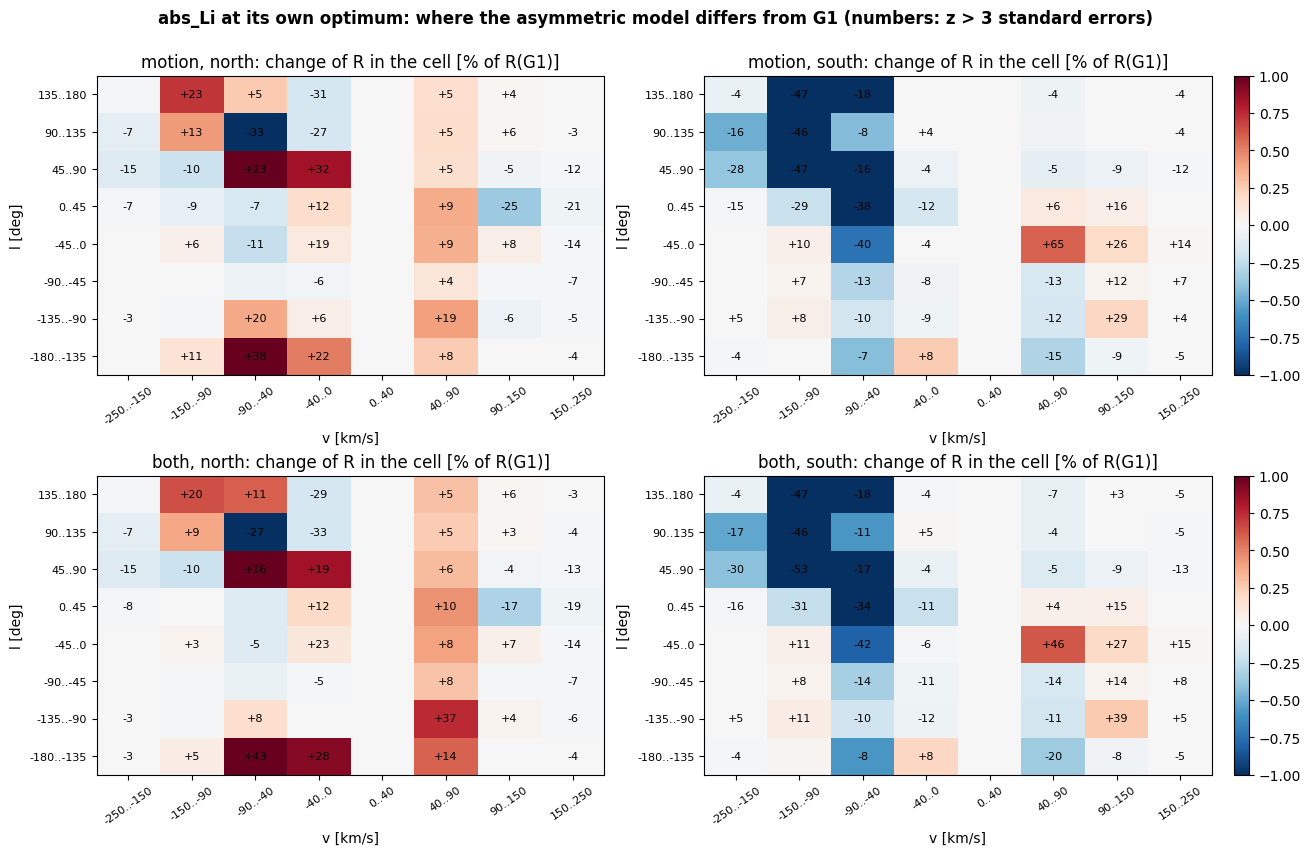

Cells beyond 3 standard errors (of 128 per stage and hemisphere. Chance alone would give about 0.7 in all):
> motion  south l  -45..  +0  v  +40.. +90:   +0.59 % of R(G1)   z = +65.3
> both    south l  +45.. +90  v -150.. -90:   -1.79 % of R(G1)   z = -53.1
> motion  south l  +45.. +90  v -150.. -90:   -1.67 % of R(G1)   z = -47.3
> both    south l +135..+180  v -150.. -90:   -1.37 % of R(G1)   z = -47.1
> motion  south l +135..+180  v -150.. -90:   -1.30 % of R(G1)   z = -46.7
> both    south l  -45..  +0  v  +40.. +90:   +0.62 % of R(G1)   z = +46.2
> motion  south l  +90..+135  v -150.. -90:   -2.20 % of R(G1)   z = -45.9
> both    south l  +90..+135  v -150.. -90:   -2.51 % of R(G1)   z = -45.9
> both    north l -180..-135  v  -90.. -40:   +2.74 % of R(G1)   z = +43.2
> both    south l  -45..  +0  v  -90.. -40:   -0.81 % of R(G1)   z = -42.1
> motion  south l  -45..  +0  v  -90.. -40:   -0.74 % of R(G1)   z = -39.6
> both    south l -135.. -90  v  +90..+150:   +0.27 % of R(G1)   z 

In [19]:
if "G1" in CS:
    tot = CS["G1"].sum((1, 2, 3)).mean()
    fig, axs = plt.subplots(2, 2, figsize=(13, 8), constrained_layout=True)
    TOP = []

    for r, lab_ in enumerate([l_ for l_ in C_LAB[1:] if l_ in CS]):
        d = CS[lab_].mean(0) - CS["G1"].mean(0)
        se = np.sqrt(CS[lab_].var(0, ddof=1) / len(CS[lab_]) + CS["G1"].var(0, ddof=1) / len(CS["G1"]))
        z = d / np.where(se > 0, se, np.nan)

        for h, hn in ((1, "north"), (0, "south")):
            ax = axs[r, 0 if h == 1 else 1]
            im = ax.imshow(100 * d[h] / tot, origin="lower", cmap="RdBu_r", vmin=-1.0, vmax=1.0, aspect="auto")

            for i in range(NL):
                for j in range(NV):
                    if np.isfinite(z[h, i, j]) and abs(z[h, i, j]) > 3:
                        ax.text(j, i, f"{z[h, i, j]:+.0f}", ha="center", va="center", fontsize=8, color="k")

            ax.set_xticks(range(NV))
            ax.set_xticklabels([f"{int(a)}..{int(b)}" for a, b in zip(V_BINS[:-1], V_BINS[1:])], rotation=35, fontsize=8)
            ax.set_yticks(range(NL))
            ax.set_yticklabels([f"{int(a)}..{int(b)}" for a, b in zip(L_SEC[:-1], L_SEC[1:])], fontsize=8)

            ax.set(title=f"{lab_}, {hn}: change of R in the cell [% of R(G1)]", xlabel="v [km/s]", ylabel="l [deg]")
            for i in range(NL):
                for j in range(NV):
                    if np.isfinite(z[h, i, j]) and abs(z[h, i, j]) > 3: 
                        TOP.append((abs(z[h, i, j]), 
                                    lab_, 
                                    hn, 
                                    L_SEC[i], 
                                    L_SEC[i + 1], 
                                    V_BINS[j], 
                                    V_BINS[j + 1], 
                                    100 * d[h, i, j] / tot, 
                                    z[h, i, j]))
                        
        fig.colorbar(im, ax=axs[r, :], fraction=0.025, pad=0.02)
    fig.suptitle(f"{C_KEY} at its own optimum: where the asymmetric model differs from G1 (numbers: z > 3 standard errors)", 
                 y=1.05, weight="bold")

    plt.show()

    print(f"Cells beyond 3 standard errors (of {2 * NL * NV} per stage and hemisphere. "
          f"Chance alone would give about {0.0027 * 2 * NL * NV * 2:.1f} in all):")
    
    for t in sorted(TOP, reverse=True)[:14]: 
        print(f"> {t[1]:7s} {t[2]:5s} l {t[3]:+4.0f}..{t[4]:+4.0f}  v {t[5]:+4.0f}..{t[6]:+4.0f}:  {t[7]:+6.2f} % "
              f"of R(G1)   z = {t[8]:+.1f}")
    print(f"\nThe total change of R per hemisphere (north + south = the whole): " + \
          "  ".join(f"{l_}: N {100 * (CS[l_].mean(0)[1] - CS['G1'].mean(0)[1]).sum() / tot:+.2f} %  " + \
                    f"S {100 * (CS[l_].mean(0)[0] - CS['G1'].mean(0)[0]).sum() / tot:+.2f} %" for l_ in C_LAB[1:] if l_ in CS))

*(Model and LAB maps are the mean over the channels of the bin of the comparison cube; the Magellanic masks are the ones of the comparison, so inside them nothing is compared. A voxel that is compared in only one of the two models has its whole residual counted in the change: those edge effects are the footprint differences of the two models, and show up as isolated spots.)*

/tmp/ipykernel_13305/249611675.py:26: RuntimeWarning: Mean of empty slice
  Dm = np.nanmean(FG[0][sel], axis=0)
/tmp/ipykernel_13305/249611675.py:27: RuntimeWarning: Mean of empty slice
  Mg = np.nanmean(FG[1][sel], axis=0)
/tmp/ipykernel_13305/249611675.py:28: RuntimeWarning: Mean of empty slice
  Ma = np.nanmean(FA[1][sel], axis=0)
/tmp/ipykernel_13305/249611675.py:26: RuntimeWarning: Mean of empty slice
  Dm = np.nanmean(FG[0][sel], axis=0)
/tmp/ipykernel_13305/249611675.py:27: RuntimeWarning: Mean of empty slice
  Mg = np.nanmean(FG[1][sel], axis=0)
/tmp/ipykernel_13305/249611675.py:28: RuntimeWarning: Mean of empty slice
  Ma = np.nanmean(FA[1][sel], axis=0)
/tmp/ipykernel_13305/249611675.py:26: RuntimeWarning: Mean of empty slice
  Dm = np.nanmean(FG[0][sel], axis=0)
/tmp/ipykernel_13305/249611675.py:27: RuntimeWarning: Mean of empty slice
  Mg = np.nanmean(FG[1][sel], axis=0)
/tmp/ipykernel_13305/249611675.py:28: RuntimeWarning: Mean of empty slice
  Ma = np.nanmean(FA[1][sel], 

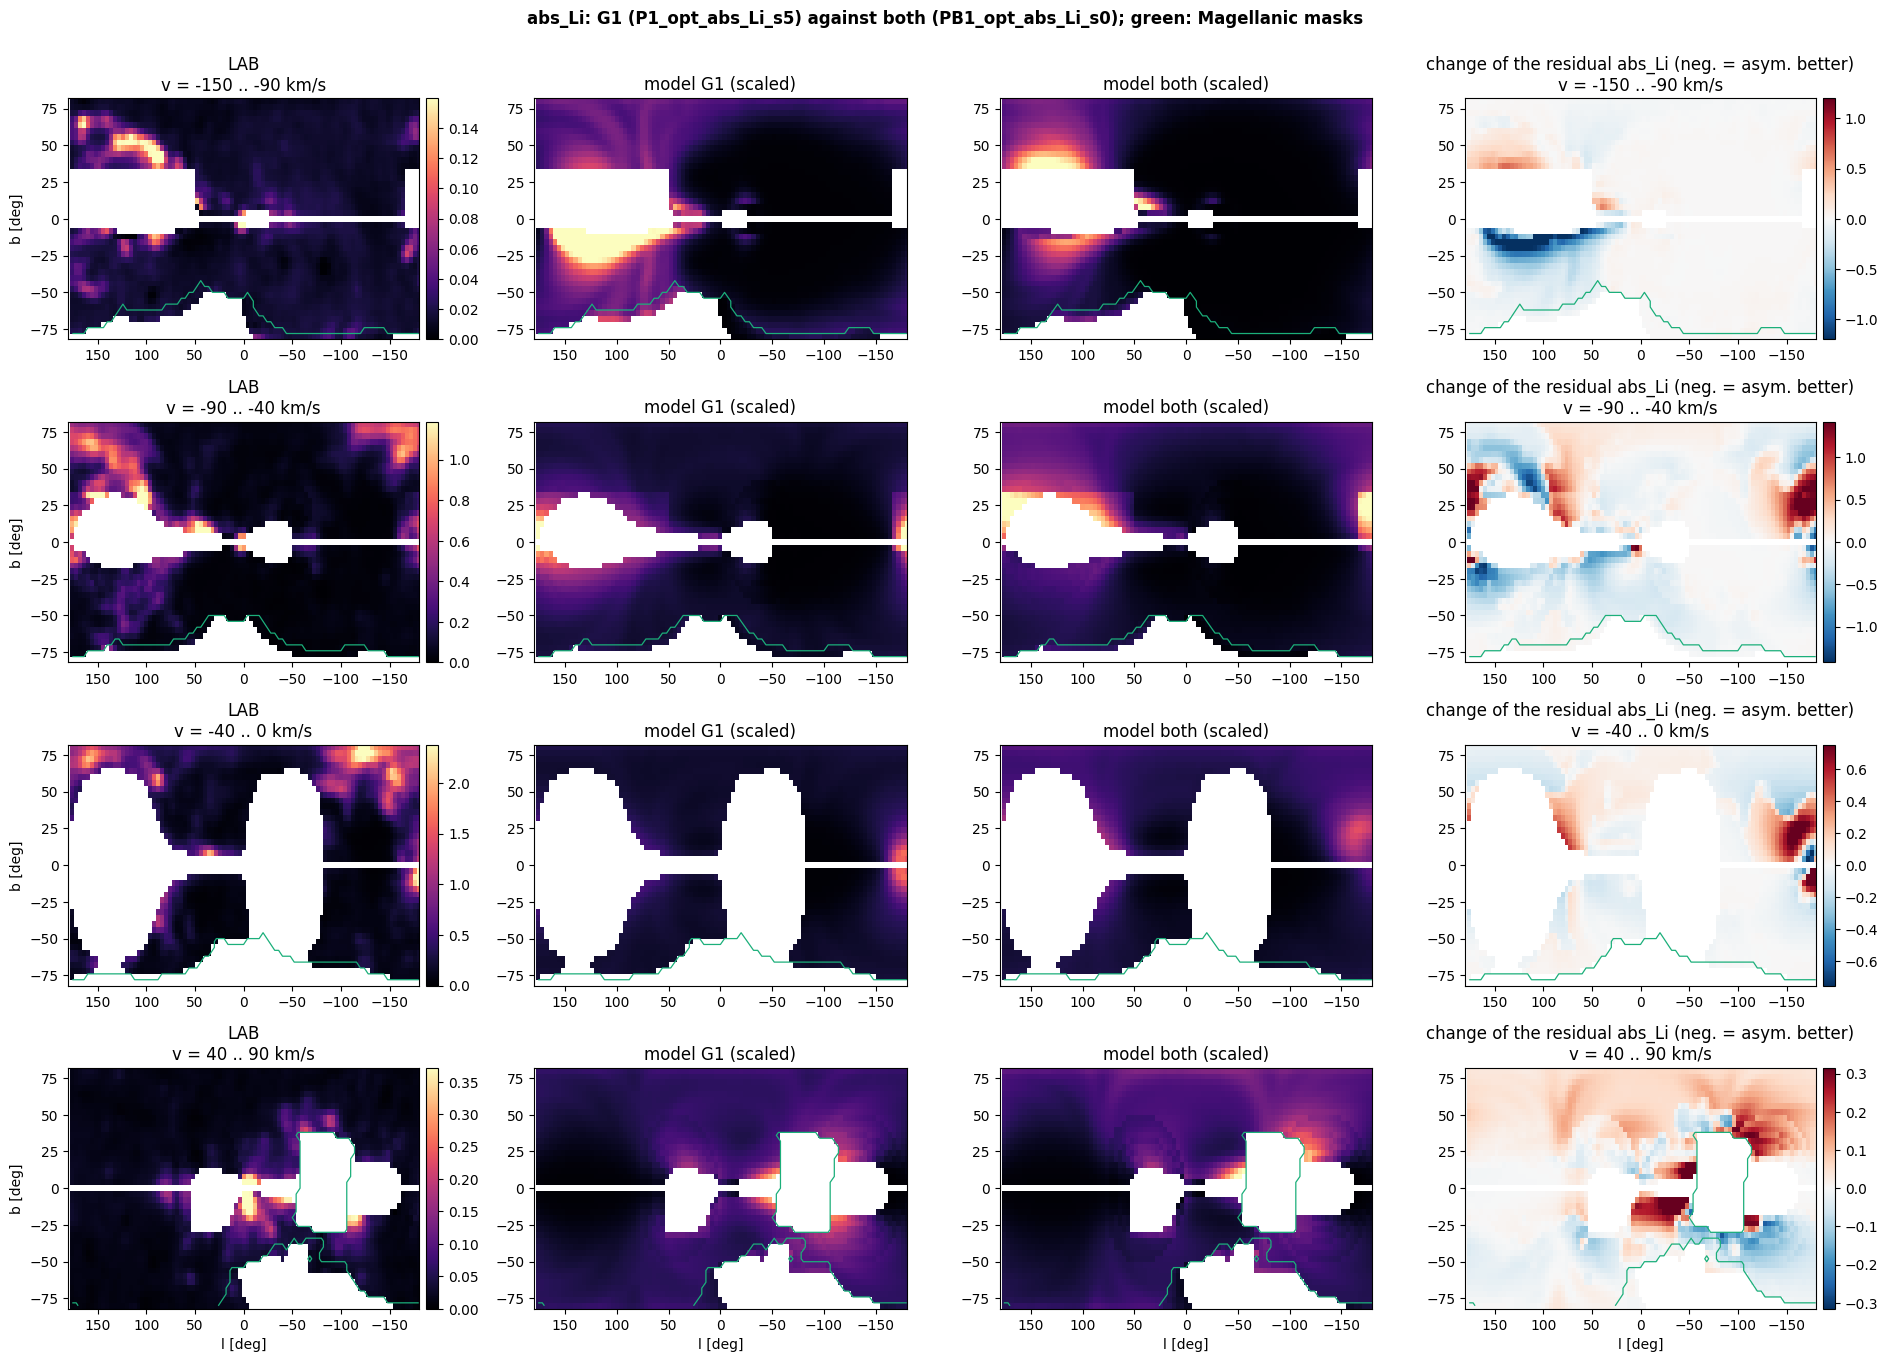

Change of the residual (sum over voxels), both minus G1, model of median R at the optimum.
The ring is one cell (8 deg, 8 km/s) around the Magellanic masks:
           net, ring    net, far   abs, ring    abs, far  (units of the total R of G1 = 2882.1)
north         +0.37%      +8.77%       0.57%      32.95%
south         -0.75%     -12.09%       2.45%      20.34%
Voxels in the ring: 15010 of 160304 compared; far: 148333


In [20]:
VSHOW = [(-150.0, -90.0), (-90.0, -40.0), (-40.0, 0.0), (40.0, 90.0)]
MAP_LABEL = "both" # The asymmetric stage to map against G1 ('motion' or 'both').

def term_cube(F, key):
    D, M, W, S, ev = F
    t = np.full(D.shape, np.nan)
    t[ev["vec"]["valid"]] = np.asarray(ev["vec"]["t"][KEYS.index(key)], float)
    return t

if MAP_LABEL in STG and "G1" in STG:
    nG, nA = best_model("G1", C_KEY), best_model(MAP_LABEL, C_KEY)
    FG, FA = field_cubes("G1", nG), field_cubes(MAP_LABEL, nA)
    TG, TA = term_cube(FG, C_KEY), term_cube(FA, C_KEY)

    dT = np.where(np.isfinite(TG) | np.isfinite(TA), np.nan_to_num(TA) - np.nan_to_num(TG), np.nan)
    lw = (np.asarray(cmp.l, float) + 180.0) % 360.0 - 180.0
    order = np.argsort(lw)
    cb, cv = np.asarray(cmp.b, float), np.asarray(cmp.v, float)
    mag = mask_named_regions(cmp.l, cmp.b, cmp.v, MAGELLANIC)

    fig, axs = plt.subplots(len(VSHOW), 4, figsize=(19, 3.4 * len(VSHOW)), squeeze=False)
    for r, (v0, v1) in enumerate(VSHOW):
        sel = (cv >= v0) & (cv < v1)

        with warnings.catch_warnings():
            Dm = np.nanmean(FG[0][sel], axis=0)
            Mg = np.nanmean(FG[1][sel], axis=0)
            Ma = np.nanmean(FA[1][sel], axis=0)

        dm = np.nansum(np.where(np.isfinite(dT[sel]), dT[sel], 0.0), axis=0)
        dm = np.where(np.isfinite(dT[sel]).any(0), dm, np.nan)
        vmax = np.nanpercentile(Dm, 99.5); dl = np.nanpercentile(np.abs(dm), 99)

        for c, (arr, ttl, kw) in enumerate(((Dm, "LAB", dict(cmap="magma", vmin=0, vmax=vmax)), 
                                            (Mg, "model G1 (scaled)", dict(cmap="magma", vmin=0, vmax=vmax)),
                                            (Ma, f"model {MAP_LABEL} (scaled)", dict(cmap="magma", vmin=0, vmax=vmax)), 
                                            (dm, f"change of the residual {C_KEY} (neg. = asym. better)", 
                                             dict(cmap="RdBu_r", vmin=-dl, vmax=dl)))):
            
            ax = axs[r, c]
            im = ax.pcolormesh(lw[order], cb, arr[:, order], shading="nearest", rasterized=True, **kw)
            m2 = mag[sel].any(0)
            if m2.any(): 
                ax.contour(lw[order], cb, m2[:, order].astype(float), levels=[0.5], colors="#1baf7a", linewidths=0.9)
            ax.set_xlim(180, -180)
            ax.set(title=f"{ttl}\nv = {v0:.0f} .. {v1:.0f} km/s" if c in (0, 3) else ttl, 
                   xlabel="l [deg]" if r == len(VSHOW) - 1 else "", ylabel="b [deg]" if c == 0 else "")
            if c in (0, 3):
                fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02)

    fig.suptitle(f"{C_KEY}: G1 ({nG}) against {MAP_LABEL} ({nA}); green: Magellanic masks", y=0.998, weight="bold")

    plt.tight_layout()
    plt.show()

    # How much of the change sits in a ring around the Magellanic masks?
    from scipy.ndimage import binary_dilation
    ring_d = binary_dilation(mag, structure=np.ones((3, 5, 5), bool)) & ~mag
    far = ~binary_dilation(mag, structure=np.ones((3, 5, 5), bool))

    nrth = (cb > 0)[None, :, None] & np.ones(dT.shape, bool)
    sth = (cb < 0)[None, :, None] & np.ones(dT.shape, bool)

    print(f"Change of the residual (sum over voxels), {MAP_LABEL} minus G1, model of median R at the optimum.\n"
          "The ring is one cell (8 deg, 8 km/s) around the Magellanic masks:")
    print(f"{'':8s} {'net, ring':>11s} {'net, far':>11s} {'abs, ring':>11s} {'abs, far':>11s}  "
          f"(units of the total R of G1 = {np.nansum(TG):.5g})")
    
    for nm, hm in (("north", nrth), ("south", sth)):
        a = lambda m: np.nansum(np.where(m, dT, 0.0))
        b = lambda m: np.nansum(np.where(m & np.isfinite(dT), np.abs(dT), 0.0))
        print(f"{nm:8s} {100 * a(hm & ring_d) / np.nansum(TG):+10.2f}% {100 * a(hm & far) / np.nansum(TG):+10.2f}% "
              f"{100 * b(hm & ring_d) / np.nansum(TG):10.2f}% {100 * b(hm & far) / np.nansum(TG):10.2f}%")
        
    print(f"Voxels in the ring: {ring_d.sum()} of {np.isfinite(dT).sum()} compared; far: {(far & np.isfinite(dT)).sum()}")

## 7. The footprint of the north-south floor

In Part 3, we found that a symmetric model cannot get below ~44 % of $R$ (`abs_Li`, structural part). The difference between LAB at $+b$ and at $-b$ for the same $(l, |b|, v)$. 

Then, we can ask: where does that floor sit? If most of it is in pairs where one side has emission and the other has none (a clump, a cloud, a piece of a stream, an unmasked complex on one side only), we should be able to consider it as a *footprint* property of the sky that no wind will fix, and the asymmetric model's 5 % of it is what is left for physics. 

If most of it is amplitude differences where both sides emit, a hemisphere-dependent normalization or gas distribution (Part 6) is the natural thing to look at.

For the pairs of the best symmetric model (`G1`), the closed-form `abs` floor $w |D_N - D_S|$ is split by the class of the pair: both sides above $k\sigma$, only north, only south, neither ($k = 3$). The noise part ($2\sigma/\sqrt\pi$ per pair, from a mock) is subtracted class by class. Also show is the part of the `abs` residual of the `G1` model itself that lies in each class.

71572 pairs; closed-form abs floor 1276.2, noise part 174.73, structural 1101.5;
abs residual of the best G1 model on these pairs 2416.9

class (3.0 sigma)     pairs  % pairs |      floor      noise  structural  % of struct. |  R(G1) there  % of R  floor/R
both sides emit       23696     33.1 |     1053.9     60.104      993.82         90.2% |       1943.6   80.4%     0.54
north only             6670      9.3 |     84.614     16.613      68.001          6.2% |       153.08    6.3%     0.55
south only             8381     11.7 |     54.862     18.551      36.311          3.3% |       119.59    4.9%     0.46
neither               32825     45.9 |     82.844     79.458      3.3864          0.3% |       200.69    8.3%     0.41


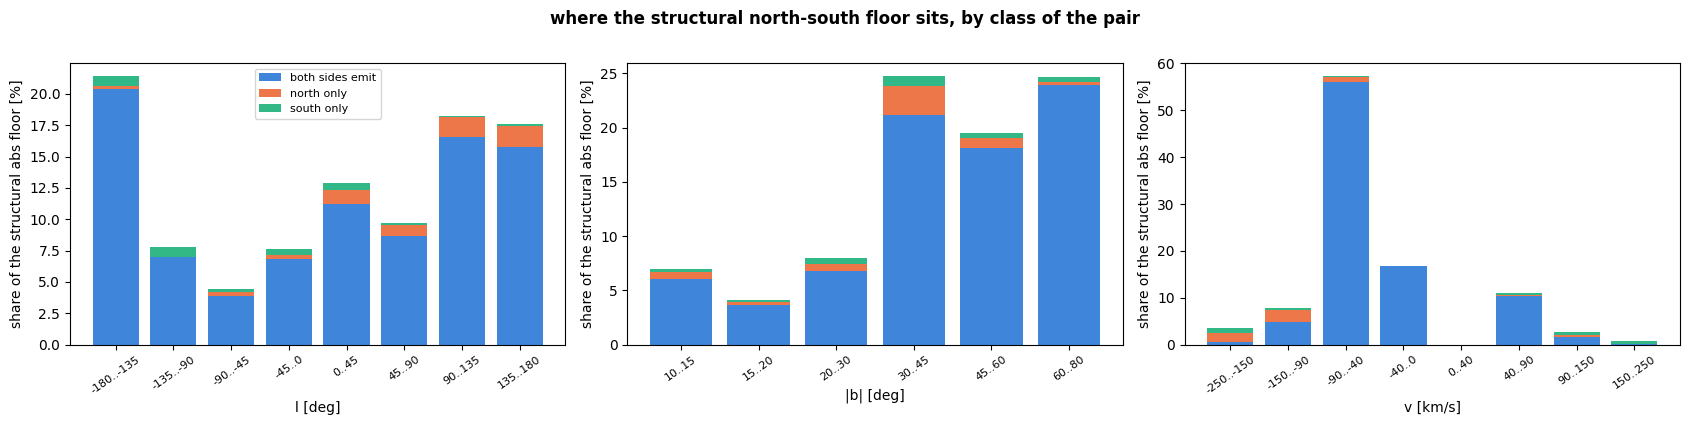

In [21]:
D_SIG = 3.0

def pair_arrays_idx(vec):
    """
    The voxel pairs (+b, -b) valid in data and model on both sides: 
    DN, DS, w, MN, MS and their (v index, b [deg, positive side], l index).
    """

    shape = cmp.lab_cmp.data.shape
    D = np.full(shape, np.nan); M = np.full(shape, np.nan)
    D[vec["valid"]] = vec["d"]; M[vec["valid"]] = vec["m"]
    b = np.asarray(cmp.b, float)

    iN = [i for i in range(len(b)) if b[i] > 0 and np.min(np.abs(b + b[i])) < 1e-6]
    iS = [int(np.argmin(np.abs(b + b[i]))) for i in iN]

    DN, DS, MN, MS = D[:, iN, :], D[:, iS, :], M[:, iN, :], M[:, iS, :]
    ok = np.isfinite(DN) & np.isfinite(DS) & np.isfinite(MN) & np.isfinite(MS)

    W = np.broadcast_to(np.asarray(cmp.w_b, float)[iN][None, :, None], DN.shape)
    iv, ib, il = np.nonzero(ok)

    return DN[ok], DS[ok], W[ok], MN[ok], MS[ok], iv, b[np.array(iN)][ib], il

FG0 = field_cubes("G1", best_model("G1"))
dn, ds, ww, mn, ms, iv_, bb_, il_ = pair_arrays_idx(FG0[4]["vec"])
tN, tS = dn > D_SIG * SIGMA_NUM, ds > D_SIG * SIGMA_NUM
CLASSES = [("both sides emit", tN & tS, "#2a78d6"), 
           ("north only", tN & ~tS, "#eb6834"), 
           ("south only", ~tN & tS, "#1baf7a"), 
           ("neither", ~tN & ~tS, "#8d8c88")]

f_abs = ww * np.abs(dn - ds)
rng = np.random.default_rng(11); tm = np.clip(0.5 * (dn + ds), 0.0, None)
f_noise = np.mean([ww * np.abs(tm + SIGMA_NUM * rng.standard_normal(tm.shape) - (
                    tm + SIGMA_NUM * rng.standard_normal(tm.shape))) for _ in range(6)], axis=0)

f_struct = f_abs - f_noise
# abs residual of the G1 model on the same pairs (soft set, no selection).
R_g1 = ww * (np.abs(dn - mn) + np.abs(ds - ms))

print(f"{len(dn)} pairs; closed-form abs floor {f_abs.sum():.5g}, noise part {f_noise.sum():.5g}, "
      f"structural {f_struct.sum():.5g};\nabs residual of the best G1 model on these pairs {R_g1.sum():.5g}\n")
print(f"{'class (' + str(D_SIG) + ' sigma)':18s} {'pairs':>8s} {'% pairs':>8s} | "
      f"{'floor':>10s} {'noise':>10s} {'structural':>11s} {'% of struct.':>13s} | "
      f"{'R(G1) there':>12s} {'% of R':>7s} {'floor/R':>8s}")

for nm, m, _ in CLASSES:
    print(f"{nm:18s} {m.sum():8d} {100 * m.mean():8.1f} | {f_abs[m].sum():10.5g} {f_noise[m].sum():10.5g} "
          f"{f_struct[m].sum():11.5g} {100 * f_struct[m].sum() / f_struct.sum():12.1f}% | "
          f"{R_g1[m].sum():12.5g} {100 * R_g1[m].sum() / R_g1.sum():6.1f}% {f_abs[m].sum() / R_g1[m].sum():8.2f}")

fig, axs = plt.subplots(1, 3, figsize=(17, 4.2))
lw_ = (np.asarray(cmp.l, float)[il_] + 180.0) % 360.0 - 180.0
isec = np.clip(np.digitize(lw_, L_SEC) - 1, 0, 7) if "L_SEC" in globals() else np.clip(((lw_ + 180) // 45).astype(int), 0, 7)
ib_ = np.clip(np.digitize(bb_, B_BINS) - 1, -1, len(B_BINS) - 1)
iv2 = np.digitize(np.asarray(cmp.v, float)[iv_], V_BINS) - 1

for ax, idx, n, edges, name in ((axs[0], isec, 8, np.arange(-180, 181, 45), "l [deg]"), 
                                (axs[1], ib_, len(B_BINS) - 1, B_BINS, "|b| [deg]"), 
                                (axs[2], iv2, len(V_BINS) - 1, V_BINS, "v [km/s]")):
    bottom = np.zeros(n)
    for nm, m, col in CLASSES[:3]:
        ok = m & (idx >= 0) & (idx < n)
        vals = np.bincount(idx[ok], weights=f_struct[ok], minlength=n)[:n] / f_struct.sum() * 100
        ax.bar(range(n), vals, bottom=bottom, color=col, alpha=0.9, label=nm)
        bottom += vals

    ax.set_xticks(range(n))
    ax.set_xticklabels([f"{int(a)}..{int(b)}" for a, b in zip(edges[:-1], edges[1:])], rotation=35, fontsize=8)
    ax.set(xlabel=name, ylabel="share of the structural abs floor [%]")

axs[0].legend(fontsize=8)
fig.suptitle("where the structural north-south floor sits, by class of the pair", y=1.0, weight="bold")

plt.tight_layout()
plt.show()

**Reading it.** 

The *floor/R* column is how much of the `G1` residual in that class no symmetric model could remove. A class with a large share of the structural floor **and** emission on one side only is the footprint (clumps and complexes that exist on one side). The class `"both sides emit"` is where an amplitude asymmetry lives, the only place a normalization or a wind can act.
We see that, aligning with what we have seen so far, this is roughly half of the data. The distribution of where this lies varies substantially.

## 8. Stage `PR2`: two hemispheres, two winds, run for real (one `heron` job, 66 runs)

**What the model does now:** One body, the corona, moves with a velocity $-v_{\rm motion}$ in the north run and (by the flip) the same real velocity in the south run. In *head-wind* terms (positive = the corona moves towards the disc, so rising clouds meet a head wind), the north run has $h_N = v_{\rm motion}$ and the south run $h_S = -v_{\rm motion}$. Oprea et al. ($v_{\rm motion} = -40$) is $(h_N, h_S) = (-40, +40)$: a tail wind in the north, a head wind in the south.

**The learning test:** Let the two hemispheres choose $h_N$ and $h_S$ independently (everything else, $\theta = $ `hv0`, `alpha_conds`, `alpha_hv`, `f_ion`, still common). 

Write $h_N = m + c$, $h_S = -m + c$: $m$ is the part that is one motion of the whole corona (what we have now: $v_{\rm motion} = m$) and $c$ is a head wind that is the **same in both hemispheres**, which is not a motion of a rigid corona and which the symmetric parameters ($\alpha_{\rm conds}$, hv, ...) can partly mimic: it is the *price* of the decoupling, and a large fitted $c$ tells us that the symmetric model is asking for something a single $v_{\rm motion}$ cannot give.

`PR2` aims to  measure this. All places share the parameters $\theta$ of the **M1 optimum** of `abs_Li` (`hv0`, `alpha_conds`, `alpha_hv`, `f_ion`), the south ratios are 1 (as in M1: the CGM does not matter), and only the winds change, in the head-wind terms of section A, $(h_N, h_S)$, entered in the code as `v_motion` $= (h_N - h_S)/2$ and `v_motion_even` $= (h_N + h_S)/2$ (this is a new keyword only meant for diagnostics):

| place | $h_N$ | $h_S$ | what it is |
|---|---|---|---|
| 3 x 3 factorial | $-40, -10, +20$ | $+20, +40, +60$ | $R_N$ depends on $h_N$ only and $R_S$ on $h_S$ only (up to the joint flux scale): every level of one is measured with the three levels of the other, so each hemisphere curve rests on 18 runs |
| `Nm40_Sp40` (in the factorial) | $-40$ | $+40$ | Oprea et al.: one corona moving at $v_{\rm motion} = -40$ |
| `nowind` | 0 | 0 | the same $\theta$ without any wind (symmetric: half the cost) |

The M1 optimum place of `PM1` (`opt_abs_Li`: this $\theta$ and the coupled $v_{\rm motion}$ of the fit, 8 seeds) is the same model, run with the same code, so it is used as the *coupled optimum* in the analysis without re-running it. With six seeds, a place has a standard error of about ~1%.

In [22]:
PR2_STAGE, PR2_N, PR2_SEEDS, PR2_SEED0 = "PR2", 40, 6, 27000 # seeds 27000 ...
PR2_WRITE = True
HN_LEVELS, HS_LEVELS = (-40.0, -10.0, 20.0), (20.0, 40.0, 60.0)
RUNS_DIR = WORK / "runs"
PR2_FILE = RUNS_DIR / f"grid4d_{PR2_STAGE}.json"

import multi_run

fitM = pickle.load(open(ASYM["motion"]["res"] / f"grid_fit_{TAG}.pkl", "rb"))["out"] \
    if (ASYM["motion"]["res"] / f"grid_fit_{TAG}.pkl").exists() else None

if fitM is None:
    print("The fit of M1 is not stored: run the M1 notebook up to step 5 first.")
else:
    # hv0, alpha_conds, alpha_hv, f_ion of the M1 optimum.
    th_c = np.asarray(fitM["abs_Li"]["est"]["theta_mean_opt"], float)[:4]
    names2 = ["hv0", "alpha_conds", "alpha_hv", "f_ion", "v_motion", "v_motion_even"]

    def place2(th4, hN, hS): return np.concatenate([th4, [0.5 * (hN - hS), 0.5 * (hN + hS)]])
    def pname(hN, hS): return f"N{'m' if hN < 0 else 'p'}{abs(hN):.0f}_S{'m' if hS < 0 else 'p'}{abs(hS):.0f}"

    PR2_POINTS = {pname(hN, hS): place2(th_c, hN, hS) for hN in HN_LEVELS for hS in HS_LEVELS}
    PR2_POINTS["nowind"] = place2(th_c, 0.0, 0.0)

    FIXED2 = gr.fixed_from_run_conv(varied=tuple(names2))
    FIXED2.update(v_kick=0.0)

    if PR2_FILE.exists():
        PR2_RUNS = g.load_runs(PR2_FILE)
        print(f"{PR2_FILE.name} exists: loaded, not regenerated.")
    elif PR2_WRITE:
        PR2_RUNS = gr.design_replicates(PR2_POINTS, PR2_STAGE, PR2_N, PR2_SEEDS, PR2_SEED0, names2, FIXED2)
        clash = gr.seeds_used_elsewhere(RUNS_DIR, PR2_STAGE) & {r["seed"] for r in PR2_RUNS.values()}
        assert not clash, f"Seeds already used by another stage: {sorted(clash)[:5]}."
        print("Run file:", g.save_runs(PR2_RUNS, PR2_FILE))
    else:
        PR2_RUNS = None; print("PR2_WRITE = False: nothing written.")
    if PR2_RUNS:
        print(f"\n{len(PR2_RUNS)} runs = {len(PR2_POINTS)} places x {PR2_SEEDS} seeds\n")
        print(f"{'place':12s} {'h_N':>6s} {'h_S':>6s} " + " ".join(f"{n:>12s}" for n in names2))
        for lab_, th in PR2_POINTS.items(): print(f"{lab_:12s} {th[4] + th[5]:+6.1f} {-th[4] + th[5]:+6.1f} " + " ".join(f"{x:12.3f}" for x in th))
        est = gr.job_estimate(PR2_RUNS, PROBE_MIN, PROBE_MB, workers=len(PR2_RUNS), n_probe=PROBE_N, slow=1.0); gr.memory_advice(est, current_gb=256)
        print(f"\nOn heron: copy the NEW mw_cube.py and multi_run.py (v_motion_even) to the code folder, in mw_grid.sub set   STAGE = {PR2_STAGE}   and   NWORK = {len(PR2_RUNS)}, then condor_submit as for the other check stages.")

grid4d_PR2.json exists: loaded, not regenerated.

66 runs = 10 places x 6 seeds

place           h_N    h_S          hv0  alpha_conds     alpha_hv        f_ion     v_motion v_motion_even
Nm40_Sp20     -40.0  +20.0       72.828        9.035        0.000        0.000      -30.000      -10.000
Nm40_Sp40     -40.0  +40.0       72.828        9.035        0.000        0.000      -40.000        0.000
Nm40_Sp60     -40.0  +60.0       72.828        9.035        0.000        0.000      -50.000       10.000
Nm10_Sp20     -10.0  +20.0       72.828        9.035        0.000        0.000      -15.000        5.000
Nm10_Sp40     -10.0  +40.0       72.828        9.035        0.000        0.000      -25.000       15.000
Nm10_Sp60     -10.0  +60.0       72.828        9.035        0.000        0.000      -35.000       25.000
Np20_Sp20     +20.0  +20.0       72.828        9.035        0.000        0.000        0.000       20.000
Np20_Sp40     +20.0  +40.0       72.828        9.035        0.000        0.000

**After the `PR2` job.** 

We evaluate the pack (merged pack and cache in the diagnostics folder), and the replicates give: the table of $R$ per place; the **separability check** ($R_N$ must not depend on $h_S$, $R_S$ not on $h_N$, up to the joint scale); the hemisphere curves $R_N(h_N)$ and $R_S(h_S)$ through three levels each (a parabola, with a bootstrap over the replicates for its minimum); the **coupled** optimum on the diagonal $h_S = -h_N$ against the **decoupled** one, and the emulator's prediction against both.

In [23]:
PR2_PACKS = sorted(WORK.glob(f"out_{PR2_STAGE}_*/pack.fits"))
if not PR2_PACKS:
    print("No pack of PR2 yet: run the job and copy the pack (the commands are printed above), then run this cell again.")
else:
    pack2 = gr.open_packs(PR2_PACKS, DIAG / "pack_PR2.fits")
    RES_PR2 = gr.evaluate_pack(pack2, cmp, cache=DIAG / f"grid_resid_PR2_{TAG}.pkl", workers=WORKERS)
    RUNS_PR2 = pack2.runs()
    STG["PR2"] = dict(label="PR2", 
                      stage=PR2_STAGE, 
                      check=PR2_STAGE, 
                      RES=RES_PR2, 
                      RUNS=RUNS_PR2)
    STG["PR2"]["REP"] = rep_groups(RES_PR2, PR2_STAGE)
    REP2 = STG["PR2"]["REP"]
    WIND = {p: (RUNS_PR2[ns[0]]["kw"]["v_motion"] + RUNS_PR2[ns[0]]["kw"].get("v_motion_even", 0.0), 
                -RUNS_PR2[ns[0]]["kw"]["v_motion"] + RUNS_PR2[ns[0]]["kw"].get("v_motion_even", 0.0)) for p, ns in REP2.items()}
    order = sorted(REP2, key=lambda p: (WIND[p][0], WIND[p][1]))
    show = ["abs_Li", "abs", "rel_Li", "sq_Li"]
    ref = "Nm40_Sp40"
    print(f"R of every place (mean +- standard error over the replicates; % against {ref} = "
          f"Oprea's one-corona picture at the same theta):\n")
    print(f"{'place':10s} {'h_N':>5s} {'h_S':>5s} {'n':>3s} " + " ".join(f"{k:>22s}" for k in show))

    for p in order:
        row = f"{p:10s} {WIND[p][0]:+5.0f} {WIND[p][1]:+5.0f} {len(REP2[p]):3d} "
        for k in show:
            a = rep_stat(STG["PR2"], p, k)
            r = ratio(rep_stat(STG["PR2"], ref, k), a) if ref in REP2 else (np.nan, np.nan)
            row += f"{a[0]:10.5g} ({100 * r[0]:+5.1f}+-{100 * r[1]:3.1f}%) "
        print(row)

    if "opt_abs_Li" in STG["motion"]["REP"]:
        row = f"{'PM1 opt':10s} {'':>5s} {'':>5s} {len(STG['motion']['REP']['opt_abs_Li']):3d} "
        for k in show:
            a = rep_stat(STG["motion"], "opt_abs_Li", k)
            r = ratio(rep_stat(STG["PR2"], ref, k), a) if ref in REP2 else (np.nan, np.nan)
            row += f"{a[0]:10.5g} ({100 * r[0]:+5.1f}±{100 * r[1]:3.1f}%) "
        print(row + "   <- the M1 optimum (coupled), run in PM1")

0 new evaluations in 0 s; 66 models evaluated
R of every place (mean +- standard error over the replicates; % against Nm40_Sp40 = Oprea's one-corona picture at the same theta):

place        h_N   h_S   n                 abs_Li                    abs                 rel_Li                  sq_Li
Nm40_Sp20    -40   +20   6     2762.6 ( -0.9+-0.3%)     2875.6 ( -0.9+-0.3%)      49896 ( -0.3+-0.5%)     858.55 ( -3.6+-0.8%) 
Nm40_Sp40    -40   +40   6     2788.5 ( +0.0+-0.3%)       2902 ( +0.0+-0.3%)      50056 ( +0.0+-0.4%)     890.28 ( +0.0+-0.6%) 
Nm40_Sp60    -40   +60   6     2792.5 ( +0.1+-0.3%)     2907.4 ( +0.2+-0.3%)      49907 ( -0.3+-0.3%)     904.91 ( +1.6+-0.9%) 
Nm10_Sp20    -10   +20   6       2812 ( +0.8+-0.4%)     2924.6 ( +0.8+-0.4%)      50518 ( +0.9+-0.4%)     831.67 ( -6.6+-0.7%) 
Nm10_Sp40    -10   +40   6     2790.5 ( +0.1+-0.4%)     2903.9 ( +0.1+-0.4%)      50386 ( +0.7+-0.5%)     817.72 ( -8.1+-0.7%) 
Nm10_Sp60    -10   +60   6     2784.3 ( -0.2+-0.7%)     2895.8 

In [24]:
def groups_by_level(field, which, key):
    """ {level: {place: [values]}} for the factorial places; which = 0 (north level h_N) or 1 (south level h_S). """
    G = {}
    for p, ns in REP2.items():
        if p in ("nowind", "dec_opt") or p not in WIND:
            continue
        G.setdefault(round(WIND[p][which], 1), {})[p] = [RES_PR2[n][field] for n in ns]
    return G

def parabola(x, y):
    A = np.vander(np.asarray(x, float), 3); a, b, c = np.linalg.solve(A, np.asarray(y, float)); return a, b, c

if PR2_PACKS and "Nm40_Sp40" in REP2:
    KEY2 = "abs_Li"; rng = np.random.default_rng(3); CURVE = {}
    for which, hn, fld in ((0, "north", f"R_{KEY2}_N"), (1, "south", f"R_{KEY2}_S")):
        G = groups_by_level(fld, which, KEY2)
        lv = sorted(G)
        if len(lv) != 3: 
            print(f"{hn}: {len(lv)} levels found, 3 needed")
            continue

        pooled = {l_: np.concatenate([G[l_][p] for p in G[l_]]) for l_ in lv}
        m = np.array([pooled[l_].mean() for l_ in lv])
        se = np.array([pooled[l_].std(ddof=1) / np.sqrt(len(pooled[l_])) for l_ in lv])
        
        # Separability: do the group means at one level agree whatever the other hemisphere's wind?
        chi2 = 0.0; dof = 0
        for l_ in lv:
            mm = np.array([np.mean(v) for v in G[l_].values()])
            ss = np.array([np.std(v, ddof=1) / np.sqrt(len(v)) for v in G[l_].values()])
            chi2 += (((mm - np.average(mm, weights=1 / ss ** 2)) / ss) ** 2).sum()
            dof += len(mm) - 1

        a, b, c = parabola(lv, m)
        vtx = -b / (2 * a) if a > 0 else np.nan
        boot = []

        for _ in range(2000):
            mb = np.array([rng.choice(pooled[l_], len(pooled[l_])).mean() for l_ in lv])
            ab, bb, cb_ = parabola(lv, mb)
            boot.append(np.clip(-bb / (2 * ab), lv[0] - 30, lv[-1] + 30) if ab > 0 else np.nan)

        boot = np.array(boot)
        fin = np.isfinite(boot)
        CURVE[hn] = dict(levels=lv, mean=m, se=se, abc=(a, b, c), vertex=vtx, boot=boot)

        print(f"{hn:5s}: R_{hn[0].upper()}({KEY2}) at h = " + \
              ", ".join(f"{l_:+.0f}: {mi:.5g} +- {si:.2g} ({100 * (mi / m[0] - 1):+.1f} %)" for l_, mi, si in zip(lv, m, se)) \
              + f"\n       dependence on the other hemisphere's wind: chi2 = {chi2:.1f} for {dof} dof (expect ~{dof}); " + \
              f"\n       parabola minimum at h = {vtx:+.1f}" + \
              (f"  (bootstrap 16/50/84 %: {'/'.join(f'{x:+.0f}' for x in np.percentile(boot[fin], [16, 50, 84]))}; " + \
               f"no interior minimum in {100 * (1 - fin.mean()):.0f} % of the draws)" if fin.any() else "  (concave: no interior minimum)"))

north: R_N(abs_Li) at h = -40: 1839.3 +- 13 (+0.0 %), -10: 1697.3 +- 15 (-7.7 %), +20: 1630.3 +- 12 (-11.4 %)
       dependence on the other hemisphere's wind: chi2 = 213.2 for 6 dof (expect ~6); 
       parabola minimum at h = +31.7  (bootstrap 16/50/84 %: +19/+32/+50; no interior minimum in 1 % of the draws)
south: R_S(abs_Li) at h = +20: 1167.5 +- 34 (+0.0 %), +40: 1082.8 +- 28 (-7.3 %), +60: 1021.9 +- 25 (-12.5 %)
       dependence on the other hemisphere's wind: chi2 = 3775.0 for 6 dof (expect ~6); 
       parabola minimum at h = +101.1  (bootstrap 16/50/84 %: +53/+66/+90; no interior minimum in 36 % of the draws)


In [25]:
if PR2_PACKS and "Nm40_Sp40" in REP2:
    # The PR2 runs with ONE flux scale (as in the grid searches) and with each hemisphere on its OWN scale.
    # The decomposition of s_S / s_N.
    RES_PR2H = gr.evaluate_pack(pack2, cmp, cache=DIAG / f"resid_PR2_hemi_{TAG}.pkl", workers=WORKERS, fn=hemi_eval_fn(False))
    WR = {p: (round(WIND[p][0], 1), round(WIND[p][1], 1)) for p in REP2 if p in WIND}
    MC = {p: (0.5 * (WR[p][0] - WR[p][1]), 0.5 * (WR[p][0] + WR[p][1])) for p in WR}   # (m, c) of every place
    FAC = [p for p in REP2 if p in WR and p not in ("nowind", "dec_opt")]
    P_ = FAC + (["nowind"] if "nowind" in REP2 else [])

    def arr(R_, p, f): return np.array([R_[n][f] for n in REP2[p] if n in R_], float)
    def own(p): return arr(RES_PR2H, p, f"R_{KEY2}_N2") + arr(RES_PR2H, p, f"R_{KEY2}_S2")
    def joint(p): return arr(RES_PR2, p, f"R_{KEY2}")
    def se_(x): return x.std(ddof=1) / np.sqrt(len(x)) if len(x) > 1 else np.nan
    def rr(a, b):
        ma, mb = a.mean(), b.mean(); sa, sb = se_(a), se_(b)
        return ma / mb - 1.0, np.sqrt((sa / mb) ** 2 + (ma * sb / mb ** 2) ** 2)
    
    print(f"R ({KEY2}) at every place, with one flux scale for the whole sky and with one scale per hemisphere;\n"
          f"% against {ref} (Oprea); and the origin of the scale ratio, s_S/s_N = (D_S/D_N)/(M_S/M_N):\n")
    
    print(f"{'place':10s} {'m':>5s} {'c':>5s} | {'one scale':>9s} {'vs Oprea':>13s} | "
          f"{'own scales':>10s} {'vs Oprea':>13s} | {'s_S/s_N':>8s} {'D_S/D_N':>8s} {'M_S/M_N':>8s}")
    
    for p in sorted(MC, key=lambda p: (MC[p][0], MC[p][1])):
        j_, o_ = joint(p), own(p); rj, ro = rr(j_, joint(ref)), rr(o_, own(ref))
        ss = np.array([RES_PR2H[n]["scale_S"] / RES_PR2H[n]["scale_N"] for n in REP2[p]])
        dd = np.array([RES_PR2H[n]["D_S"] / RES_PR2H[n]["D_N"] for n in REP2[p]])
        mm_ = np.array([RES_PR2H[n]["M_S"] / RES_PR2H[n]["M_N"] for n in REP2[p]])

        print(f"{p:10s} {MC[p][0]:+5.0f} {MC[p][1]:+5.0f} | {j_.mean():9.5g} {100 * rj[0]:+6.1f}+-{100 * rj[1]:3.1f}% "
              f"| {o_.mean():10.5g} {100 * ro[0]:+6.1f}+-{100 * ro[1]:3.1f}% | "
              f"{ss.mean():8.3f} {dd.mean():8.3f} {mm_.mean():8.3f}")

    # ---- the landscape in (m, c):  ln R = a + b1 m + b2 m^2 + b3 c  (bootstrap over the seeds of every place)
    XP = np.array([[1.0, MC[p][0], MC[p][0] ** 2, MC[p][1]] for p in P_])

    def landscape(getter, name, B=3000):
        V = {p: np.log(getter(p)) for p in P_}
        rng = np.random.default_rng(5)
        ym = np.array([V[p].mean() for p in P_])
        sem = np.array([se_(V[p]) for p in P_])
        b = np.linalg.lstsq(XP, ym, rcond=None)[0]
        rms4 = np.sqrt(((ym - XP @ b) ** 2).sum() / (len(P_) - 4))
        b3 = np.linalg.lstsq(XP[:, :3], ym, rcond=None)[0]
        rms3 = np.sqrt(((ym - XP[:, :3] @ b3) ** 2).sum() / (len(P_) - 3))
        vt, cc, cost = [], [], []

        for _ in range(B):
            yb = np.array([rng.choice(V[p], len(V[p])).mean() for p in P_])
            bb = np.linalg.lstsq(XP, yb, rcond=None)[0]
            cc.append(100 * 20 * bb[3])
            if bb[2] > 0: 
                v0 = -bb[1] / (2 * bb[2])
                vt.append(v0)
                cost.append(100 * (bb[1] * -40 + bb[2] * 1600 - bb[1] * v0 - bb[2] * v0 ** 2))

        vt, cost = np.array(vt), np.array(cost)
        vh = -b[1] / (2 * b[2]) if b[2] > 0 else np.nan

        print(f"{name}: ln R = a + b1 m + b2 m^2 + b3 c over {len(P_)} places;\n"
              f"scatter of the place means about the fit {100 * rms4:.2f} % (m only: {100 * rms3:.2f} %;\n"
              f"standard error of a place mean {100 * np.median(sem):.2f} %)")
        
        mlo, mhi = min(MC[p][0] for p in P_), max(MC[p][0] for p in P_)

        has_interior_minimum = len(vt) > 0 and np.isfinite(vh)

        if has_interior_minimum:
            bootstrap_min = np.percentile(vt, [16, 50, 84])
            no_min_fraction = 100 * (1 - len(vt) / B)
            outside_range = not (mlo <= vh <= mhi)
            range_note = " (OUTSIDE the explored range, so: monotonic there)"if outside_range else ""
            print(
                f"   minimum in m at {vh:+.1f} km/s{range_note} "
                f"(bootstrap 16/50/84 %: "
                f"{'/'.join(f'{x:+.0f}' for x in bootstrap_min)}; "
                f"no interior minimum in {no_min_fraction:.0f} % of the draws; "
                f"explored m: {mlo:+.0f} ... {mhi:+.0f}); "
                f"cost of m = -40 against the minimum: "
                f"{np.percentile(cost, 50):+.2f} % "
                f"(16/84 %: "
                f"{np.percentile(cost, 16):+.2f} / "
                f"{np.percentile(cost, 84):+.2f})"
            )

        else:
            print(f"   no interior minimum in m (concave fit; explored m: {mlo:+.0f} ... {mhi:+.0f}): "
                  f"R is flat or monotonic in m")

        headwind_slope = 100 * 20 * b[3]
        headwind_ci = np.percentile(cc, [16, 84])

        print(
            f"   dependence on the common head wind c: {headwind_slope:+.2f} % per +20 km/s "
            f"(bootstrap 16/84 %: {headwind_ci[0]:+.2f} / {headwind_ci[1]:+.2f})"
        )
        
        if np.isfinite(vh):
            m_values = (-60, -50, -40, -30, -20, -10, 0)

            def relative_R(m):
                return 100 * (b[1] * (m - vh) + b[2] * (m**2 - vh**2))
            
            print(f"   R(m) against its minimum:  {"  ".join(f"m={m:+.0f}: {relative_R(m):+.1f} %"for m in m_values)}")
        
        return dict(b=b, vh=vh)

    print()
    LS_J = landscape(joint, "one flux scale  ")
    print()
    LS_O = landscape(own, "own flux scales")

    # ---- each hemisphere in its own wind, with its own scale
    # (this one IS separable by construction: R_N2 sees the north model only)
    def levels_own(field, which):
        G = {}
        for p in FAC: G.setdefault(WR[p][which], {})[p] = arr(RES_PR2H, p, field)
        return G
    
    rng2 = np.random.default_rng(3)
    CURVE2 = {}
    
    for which, hn in ((0, "north"), (1, "south")):
        G = levels_own(f"R_{KEY2}_{hn[0].upper()}2", which)
        lv = sorted(G)

        if len(lv) != 3:
            print(f"{hn}: {len(lv)} levels found, 3 needed")
            continue

        pooled = {l_: np.concatenate(list(G[l_].values())) for l_ in lv}
        m_ = np.array([pooled[l_].mean() for l_ in lv]); se = np.array([se_(pooled[l_]) for l_ in lv])
        chi2 = 0.0; dof = 0

        for l_ in lv:
            mm = np.array([np.mean(v) for v in G[l_].values()])
            ss = np.array([se_(v) for v in G[l_].values()])
            chi2 += (((mm - np.average(mm, weights=1 / ss ** 2)) / ss) ** 2).sum(); dof += len(mm) - 1
        a, b, c0 = parabola(lv, m_); vtx = -b / (2 * a) if a > 0 else np.nan; boot = []

        for _ in range(2000):
            mb = np.array([rng2.choice(pooled[l_], len(pooled[l_])).mean() for l_ in lv])
            ab, bb, cb_ = parabola(lv, mb); boot.append(np.clip(-bb / (2 * ab), lv[0] - 30, lv[-1] + 30) if ab > 0 else np.nan)
        boot = np.array(boot)
        fin = np.isfinite(boot)
        CURVE2[hn] = dict(levels=lv, mean=m_, se=se, abc=(a, b, c0), vertex=vtx, boot=boot)

    if len(CURVE2) == 2:
        PNo, PSo = (lambda x: np.polyval(CURVE2["north"]["abc"], x)), (lambda x: np.polyval(CURVE2["south"]["abc"], x))
        lvN, lvS = CURVE2["north"]["levels"], CURVE2["south"]["levels"]
        xg = np.arange(lvN[0], lvN[-1] + 1e-9, 0.5)
        yg = np.arange(lvS[0], lvS[-1] + 1e-9, 0.5)
        hNb, hSb = xg[np.argmin(PNo(xg))], yg[np.argmin(PSo(yg))]
        Rd, Ro = PNo(hNb) + PSo(hSb), PNo(-40.0) + PSo(40.0)
        xc = xg[(-xg >= lvS[0]) & (-xg <= lvS[-1])]
        cpl = PNo(xc) + PSo(-xc); jc = int(np.argmin(cpl))

0 new evaluations in 0 s; 66 models evaluated
R (abs_Li) at every place, with one flux scale for the whole sky and with one scale per hemisphere;
% against Nm40_Sp40 (Oprea); and the origin of the scale ratio, s_S/s_N = (D_S/D_N)/(M_S/M_N):

place          m     c | one scale      vs Oprea | own scales      vs Oprea |  s_S/s_N  D_S/D_N  M_S/M_N
Nm40_Sp60    -50   +10 |    2792.5   +0.1+-0.3% |     2778.4   -0.3+-0.3% |    1.688    0.661    0.392
Nm40_Sp40    -40    +0 |    2788.5   +0.0+-0.3% |     2787.9   +0.0+-0.3% |    1.433    0.661    0.461
Nm10_Sp60    -35   +25 |    2784.3   -0.2+-0.7% |     2788.9   +0.0+-0.6% |    1.128    0.661    0.586
Nm40_Sp20    -30   -10 |    2762.6   -0.9+-0.3% |       2767   -0.8+-0.4% |    1.203    0.661    0.552
Nm10_Sp40    -25   +15 |    2790.5   +0.1+-0.4% |     2785.3   -0.1+-0.4% |    0.939    0.661    0.704
Np20_Sp60    -20   +40 |    2822.9   +1.2+-0.5% |     2804.5   +0.6+-0.6% |    0.847    0.661    0.781
Nm10_Sp20    -15    +5 |      2812 

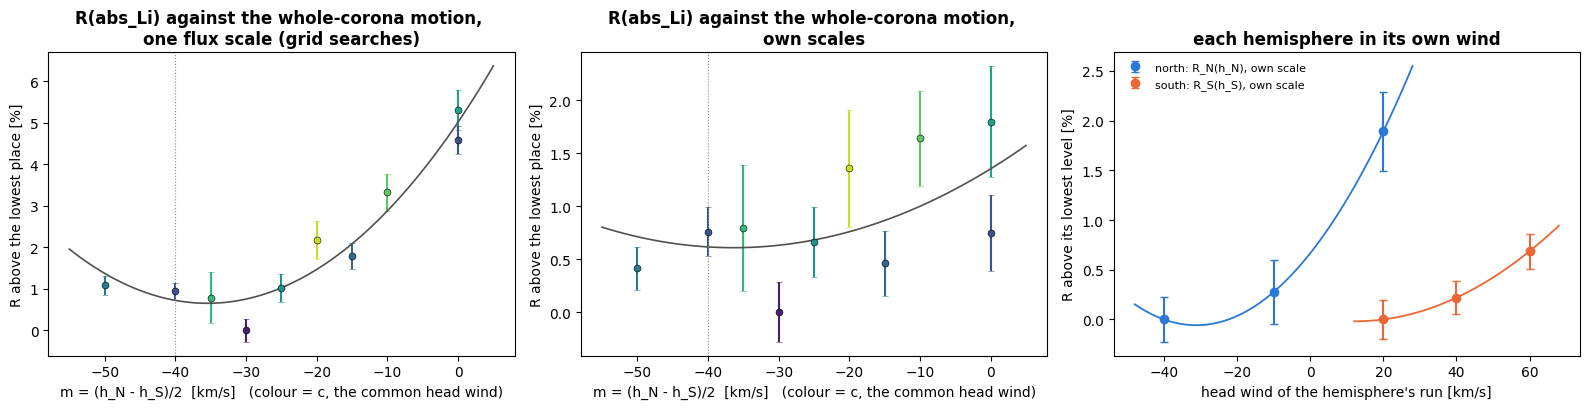

In [26]:
fig, axs = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, getter, ttl in ((axs[0], joint, "\none flux scale (grid searches)"), (axs[1], own, "\nown scales")):
    y0 = min(getter(p).mean() for p in P_)
    for p in P_:
        ax.errorbar(MC[p][0], 100 * (getter(p).mean() / y0 - 1), 100 * se_(getter(p)) / y0, 
                    fmt="o", ms=5, capsize=2, color=plt.cm.viridis((MC[p][1] + 15) / 60), mec="k", mew=0.4)
        
    LS = LS_J if getter is joint else LS_O
    mx = np.linspace(-55, 5, 100)
    cbar = np.mean([MC[p][1] for p in P_])
    ax.plot(mx, 100 * (np.exp(LS["b"][0] + LS["b"][1] * mx + LS["b"][2] * mx ** 2 + LS["b"][3] * cbar) / y0 - 1), 
            "-", color="#52514e", lw=1.2)
    ax.axvline(-40, color="#8d8c88", lw=0.8, ls=":")
    ax.set(xlabel="m = (h_N - h_S)/2  [km/s]   (colour = c, the common head wind)", 
           ylabel="R above the lowest place [%]") 
    ax.set_title(f"R({KEY2}) against the whole-corona motion, {ttl}", weight="bold")
    
if len(CURVE2) == 2:
    for hn, col in (("north", "#2a78d6"), ("south", "#eb6834")):
        C_ = CURVE2[hn]; xx = np.linspace(C_["levels"][0] - 8, C_["levels"][-1] + 8, 100)
        axs[2].errorbar(C_["levels"], 100 * (C_["mean"] / C_["mean"].min() - 1), 100 * C_["se"] / C_["mean"].min(), 
                        fmt="o", color=col, capsize=3, label=f"{hn}: R_{hn[0].upper()}(h_{hn[0].upper()}), own scale")
        axs[2].plot(xx, 100 * (np.polyval(C_["abc"], xx) / C_["mean"].min() - 1), "-", color=col, lw=1.3)

    axs[2].set(xlabel="head wind of the hemisphere's run [km/s]", 
               ylabel="R above its lowest level [%]")
    axs[2].set_title("each hemisphere in its own wind", weight="bold")
    axs[2].legend(frameon=False, fontsize=8)
    
plt.tight_layout()
plt.show()

**Reading it.**

We see that, in this experimental test, even when we decouple the hemispheres in wind speed, we see that they attain minima similar to each other, where we found the best-fit values. The remaining discrepancy can be attributed to the data itself.